# Multimodal representation learning and interpretability in medical imaging using a pre-trained model

Shaam Karym


## Setup and reproducibility



In [1]:
from pathlib import Path
import os
import sys
import subprocess
import warnings
import random
import platform

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

try:
    from tqdm.auto import tqdm
except Exception:
    tqdm = lambda x, **kwargs: x

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)


DEFAULT_DATA_DIR = "/mnt/sds-hd/sd22a004/aicmCourses/sose26/adlvmb/ADLVMB_SoSe2026/Module/Data"
DATA_DIR = Path(os.environ.get("ECHONET_DATA_DIR", DEFAULT_DATA_DIR))


VIDEO_DIR = DATA_DIR / "Videos"
FILE_LIST_PATH = DATA_DIR / "FileList.csv"
TRACINGS_PATH = DATA_DIR / "VolumeTracings.csv"

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

SPLITS = ["TRAIN", "VAL", "TEST"]

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("OpenCV:", cv2.__version__)
print("DATA_DIR:", DATA_DIR)
print("VIDEO_DIR:", VIDEO_DIR)
print("FileList exists:", FILE_LIST_PATH.exists())
print("VolumeTracings exists:", TRACINGS_PATH.exists())
print("Video folder exists:", VIDEO_DIR.exists())


Python: 3.9.25
Platform: Linux-4.18.0-553.125.1.el8_10.x86_64-x86_64-with-glibc2.28
numpy: 1.26.3
pandas: 2.2.3
OpenCV: 4.11.0
DATA_DIR: /mnt/sds-hd/sd22a004/aicmCourses/sose26/adlvmb/ADLVMB_SoSe2026/Module/Data
VIDEO_DIR: /mnt/sds-hd/sd22a004/aicmCourses/sose26/adlvmb/ADLVMB_SoSe2026/Module/Data/Videos
FileList exists: True
VolumeTracings exists: True
Video folder exists: True


## Task 1 - Data Exploration

**Assignment scope:** load and inspect the EchoNet-Dynamic metadata, videos and tracing files; display training videos; show video, intensity and clinical-measure distributions; reconstruct ESV, EDV and EF from tracing coordinates using Simpson's method; compare reconstructed values with `FileList.csv`.


In [2]:
def clean_filename(x):
    """Return file name without .avi suffix."""
    x = str(x)
    return x[:-4] if x.endswith(".avi") else x

assert FILE_LIST_PATH.exists(), f"FileList.csv not found: {FILE_LIST_PATH}"
assert TRACINGS_PATH.exists(), f"VolumeTracings.csv not found: {TRACINGS_PATH}"

df = pd.read_csv(FILE_LIST_PATH)
tracings = pd.read_csv(TRACINGS_PATH)

df["FileName_clean"] = df["FileName"].map(clean_filename)
df["VideoFileName"] = df["FileName_clean"] + ".avi"
tracings["FileName_clean"] = tracings["FileName"].map(clean_filename)

print("FileList shape:", df.shape)
print("VolumeTracings shape:", tracings.shape)
print("\nColumns in FileList:")
print(df.columns.tolist())
print("\nColumns in VolumeTracings:")
print(tracings.columns.tolist())
print("\nSplit counts:")
display(df["Split"].value_counts().rename("Number of videos").to_frame())
print("\nMissing values in FileList:")
display(df.isna().sum().rename("Missing values").to_frame())

display(df.head())
display(tracings.head())


FileList shape: (10030, 11)
VolumeTracings shape: (425010, 7)

Columns in FileList:
['FileName', 'EF', 'ESV', 'EDV', 'FrameHeight', 'FrameWidth', 'FPS', 'NumberOfFrames', 'Split', 'FileName_clean', 'VideoFileName']

Columns in VolumeTracings:
['FileName', 'X1', 'Y1', 'X2', 'Y2', 'Frame', 'FileName_clean']

Split counts:


,Number of videos
Split,
TRAIN,7465
VAL,1288
TEST,1277



Missing values in FileList:


,Missing values
FileName,0
EF,0
ESV,0
EDV,0
FrameHeight,0
FrameWidth,0
FPS,0
NumberOfFrames,0
Split,0
FileName_clean,0


,FileName,EF,ESV,EDV,FrameHeight,FrameWidth,FPS,NumberOfFrames,Split,FileName_clean,VideoFileName
0,0X100009310A3BD7FC,78.498406,14.881368,69.210534,112,112,50,174,VAL,0X100009310A3BD7FC,0X100009310A3BD7FC.avi
1,0X1002E8FBACD08477,59.101988,40.383876,98.742884,112,112,50,215,TRAIN,0X1002E8FBACD08477,0X1002E8FBACD08477.avi
2,0X1005D03EED19C65B,62.363798,14.267784,37.909734,112,112,50,104,TRAIN,0X1005D03EED19C65B,0X1005D03EED19C65B.avi
3,0X10075961BC11C88E,54.545097,33.143084,72.914210,112,112,55,122,TRAIN,0X10075961BC11C88E,0X10075961BC11C88E.avi
4,0X10094BA0A028EAC3,24.887742,127.581945,169.855024,112,112,52,207,VAL,0X10094BA0A028EAC3,0X10094BA0A028EAC3.avi


,FileName,X1,Y1,X2,Y2,Frame,FileName_clean
0,0X100009310A3BD7FC.avi,51.260417,15.348958,64.932292,69.125000,46,0X100009310A3BD7FC
1,0X100009310A3BD7FC.avi,50.037611,17.167841,53.367222,16.321330,46,0X100009310A3BD7FC
2,0X100009310A3BD7FC.avi,49.157378,20.407629,57.090549,18.390722,46,0X100009310A3BD7FC
3,0X100009310A3BD7FC.avi,48.538173,23.581055,59.997339,20.667707,46,0X100009310A3BD7FC
4,0X100009310A3BD7FC.avi,47.918968,26.754480,62.904129,22.944693,46,0X100009310A3BD7FC


In [3]:
def video_path_from_name(video_name):
    video_name = str(video_name)
    if not video_name.endswith(".avi"):
        video_name += ".avi"
    return VIDEO_DIR / video_name

def read_selected_frames(video_name, n_frames=5):
    """Read n_frames approximately equally spaced RGB frames from one video."""
    video_path = video_path_from_name(video_name)

    if not video_path.exists():
        raise FileNotFoundError(f"Video not found: {video_path}")

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"Could not open video: {video_path}")

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total_frames <= 0:
        cap.release()
        raise RuntimeError(f"No frames found in video: {video_path}")

    frame_indices = np.linspace(0, total_frames - 1, n_frames).astype(int)
    frames = []
    actual_indices = []

    for idx in frame_indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ret, frame = cap.read()
        if not ret:
            continue
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames.append(frame)
        actual_indices.append(int(idx))

    cap.release()

    if len(frames) == 0:
        raise RuntimeError(f"No readable frames in video: {video_path}")

    return frames, actual_indices

def show_video_sequence(row, n_frames=5, save_path=None):
    """Display a sequence of frames for one FileList row."""
    frames, indices = read_selected_frames(row["VideoFileName"], n_frames=n_frames)

    fig, axes = plt.subplots(1, len(frames), figsize=(3 * len(frames), 3))
    if len(frames) == 1:
        axes = [axes]

    for ax, frame, frame_idx in zip(axes, frames, indices):
        ax.imshow(frame)
        ax.axis("off")
        ax.set_title(f"Frame {frame_idx}")

    title = (
        f"{row['FileName_clean']} | Split={row['Split']} | "
        f"EF={row['EF']:.1f}% | ESV={row['ESV']:.1f} mL | EDV={row['EDV']:.1f} mL"
    )
    fig.suptitle(title)
    fig.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")

    plt.show()


### Task 1.a - Load training samples and display two randomly selected TRAIN videos

**Requirement:** load training data samples in the notebook and display one video sequence of two randomly selected training samples in the report.

Two videos are sampled from the TRAIN split using a fixed random seed. For each video, five equally spaced frames are shown so that the cardiac cycle is represented as a short sequence rather than a single still frame.


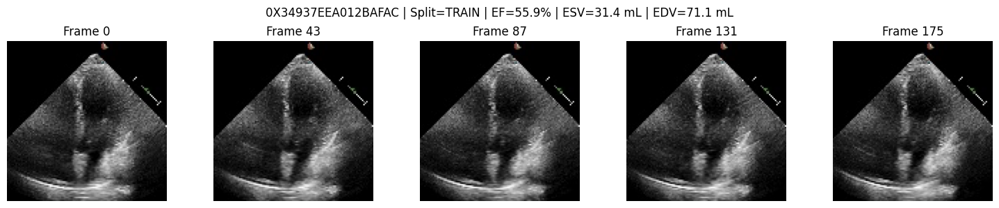

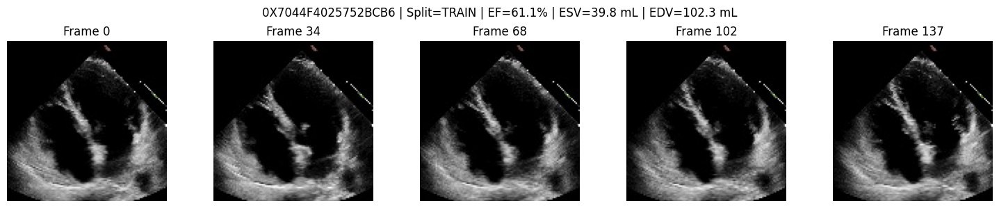

In [4]:
train_samples = (
    df[df["Split"] == "TRAIN"]
    .sample(n=2, random_state=RANDOM_SEED)
    .reset_index(drop=True)
)

for i, (_, row) in enumerate(train_samples.iterrows(), start=1):
    show_video_sequence(
        row,
        n_frames=5,
        save_path=OUT_DIR / f"task1a_training_sequence_{i}.png"
    )


### Task 1.b - Histograms of video dimensions for TRAIN, VAL and TEST

**Requirement:** show histograms of video dimensions for the TRAIN, VAL and TEST splits. Here, I inspect frame height, frame width, FPS and number of frames because these describe spatial size and temporal sampling of the videos.


FrameHeight                                         FrameWidth  \
            count        mean        std  min median  max      count   
Split                                                                  
TEST         1277  112.513704  18.357282  112  112.0  768       1277   
TRAIN        7465  112.439384  16.972958  112  112.0  768       7465   
VAL          1288  112.000000   0.000000  112  112.0  112       1288   

                                   ...       FPS                  \
             mean        std  min  ...       std min median  max   
Split                              ...                             
TEST   112.714174  25.521100  112  ...  6.860151  26   50.0  117   
TRAIN  112.612994  23.679926  112  ...  6.179323  18   50.0  138   
VAL    112.000000   0.000000  112  ...  5.910699  24   50.0  106   

      NumberOfFrames                                          
               count        mean        std min median   max  
Split                                                         
TEST            1277  177.337510  60.000546  36  173.0  1002  
TRAIN           7465  176.200938  58.681750  28  171.0  1002  
VAL             1288  177.667702  50.617567  37  174.0   690  

[3 rows x 24 columns]

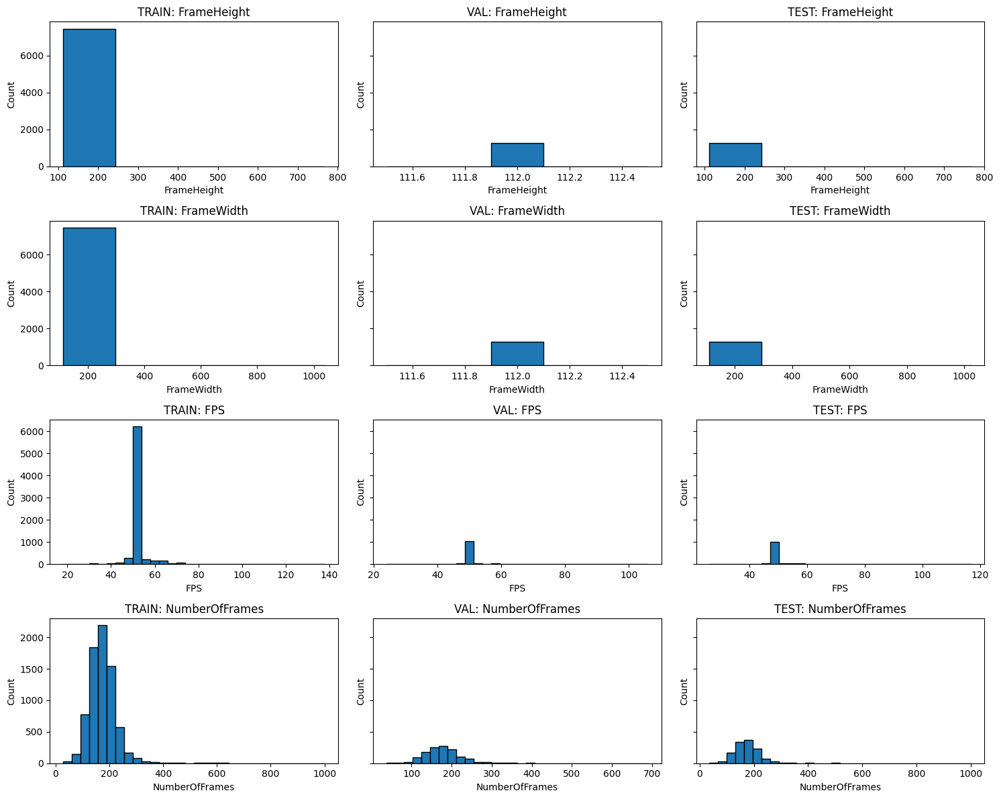

In [5]:
metadata_features = ["FrameHeight", "FrameWidth", "FPS", "NumberOfFrames"]

summary_metadata = (
    df.groupby("Split")[metadata_features]
    .agg(["count", "mean", "std", "min", "median", "max"])
)

display(summary_metadata)

fig, axes = plt.subplots(
    len(metadata_features),
    len(SPLITS),
    figsize=(15, 12),
    sharey="row"
)

for i, feature in enumerate(metadata_features):
    for j, split in enumerate(SPLITS):
        ax = axes[i, j]
        values = df.loc[df["Split"] == split, feature].dropna()
        bins = min(30, max(5, int(values.nunique())))
        ax.hist(values, bins=bins, edgecolor="black")
        ax.set_title(f"{split}: {feature}")
        ax.set_xlabel(feature)
        ax.set_ylabel("Count")

fig.tight_layout()
fig.savefig(OUT_DIR / "task1b_metadata_histograms.png", dpi=200)
plt.show()


### Task 1.c - Distribution of minimum and maximum pixel intensities

**Requirement:** show the distribution of minimum and maximum pixel intensities of all videos across TRAIN, VAL and TEST.



In [6]:
def compute_video_intensity_stats(video_name, frame_stride=1):
    """Compute min, max, mean and std of grayscale intensities for one video."""
    video_path = video_path_from_name(video_name)

    if not video_path.exists():
        return None

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        return None

    min_intensity = 255
    max_intensity = 0
    sum_intensity = 0.0
    sumsq_intensity = 0.0
    n_pixels = 0
    frame_idx = 0

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        if frame_idx % frame_stride == 0:
            gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            gray_float = gray.astype(np.float64)

            min_intensity = min(min_intensity, int(gray.min()))
            max_intensity = max(max_intensity, int(gray.max()))
            sum_intensity += gray_float.sum()
            sumsq_intensity += np.square(gray_float).sum()
            n_pixels += gray_float.size

        frame_idx += 1

    cap.release()

    if n_pixels == 0:
        return None

    mean_intensity = sum_intensity / n_pixels
    variance = max((sumsq_intensity / n_pixels) - mean_intensity ** 2, 0.0)
    std_intensity = np.sqrt(variance)

    return {
        "MinIntensity": min_intensity,
        "MaxIntensity": max_intensity,
        "MeanIntensity": mean_intensity,
        "StdIntensity": std_intensity,
        "FrameStride": frame_stride,
    }

FRAME_STRIDE = 1
INTENSITY_CACHE = OUT_DIR / f"task1c_intensity_stats_stride{FRAME_STRIDE}.csv"

if INTENSITY_CACHE.exists():
    intensity_df = pd.read_csv(INTENSITY_CACHE)
    print(f"Loaded cached intensity stats from {INTENSITY_CACHE}")
else:
    records = []
    for _, row in tqdm(df.iterrows(), total=len(df), desc="Scanning videos"):
        stats = compute_video_intensity_stats(row["VideoFileName"], frame_stride=FRAME_STRIDE)
        if stats is None:
            continue
        records.append({
            "FileName_clean": row["FileName_clean"],
            "Split": row["Split"],
            **stats,
        })

    intensity_df = pd.DataFrame(records)
    intensity_df.to_csv(INTENSITY_CACHE, index=False)

print("Videos with intensity statistics:", len(intensity_df))
display(intensity_df.head())

display(
    intensity_df.groupby("Split")[["MinIntensity", "MaxIntensity", "MeanIntensity", "StdIntensity"]]
    .agg(["count", "mean", "std", "min", "median", "max"])
)


Loaded cached intensity stats from outputs/task1c_intensity_stats_stride1.csv
Videos with intensity statistics: 10030


,FileName_clean,Split,MinIntensity,MaxIntensity,MeanIntensity,StdIntensity,FrameStride
0,0X100009310A3BD7FC,VAL,0,255,28.527899,43.392773,1
1,0X1002E8FBACD08477,TRAIN,0,255,20.747732,43.467058,1
2,0X1005D03EED19C65B,TRAIN,0,255,28.926100,46.404426,1
3,0X10075961BC11C88E,TRAIN,0,255,31.797713,46.453707,1
4,0X10094BA0A028EAC3,VAL,0,255,38.261092,51.275636,1


MinIntensity                          MaxIntensity              \
             count mean  std min median max        count        mean   
Split                                                                  
TEST          1277  0.0  0.0   0    0.0   0         1277  254.945184   
TRAIN         7465  0.0  0.0   0    0.0   0         7465  254.937843   
VAL           1288  0.0  0.0   0    0.0   0         1288  254.953416   

                      ... MeanIntensity                                   \
            std  min  ...           std        min     median        max   
Split                 ...                                                  
TEST   0.617256  243  ...      7.691550  13.142266  32.653749  65.609506   
TRAIN  0.717560  219  ...      7.917993  11.058794  32.257572  73.920263   
VAL    0.620302  237  ...      7.649318  11.800434  32.424349  59.718498   

      StdIntensity                                                        
             count       mean       std        min     median        max  
Split                                                                     
TEST          1277  49.242033  7.728997  22.947430  49.087758  75.444411  
TRAIN         7465  48.623948  7.810236  20.983365  48.615362  83.208484  
VAL           1288  48.896460  7.931370  22.017125  48.585051  76.516597  

[3 rows x 24 columns]

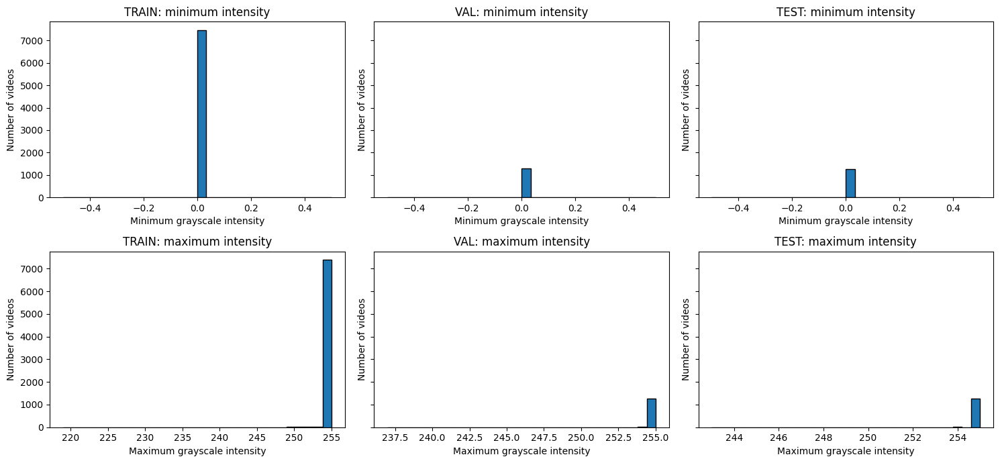

In [7]:
fig, axes = plt.subplots(2, len(SPLITS), figsize=(15, 7), sharey="row")

for j, split in enumerate(SPLITS):
    split_stats = intensity_df[intensity_df["Split"] == split]

    axes[0, j].hist(split_stats["MinIntensity"].dropna(), bins=30, edgecolor="black")
    axes[0, j].set_title(f"{split}: minimum intensity")
    axes[0, j].set_xlabel("Minimum grayscale intensity")
    axes[0, j].set_ylabel("Number of videos")

    axes[1, j].hist(split_stats["MaxIntensity"].dropna(), bins=30, edgecolor="black")
    axes[1, j].set_title(f"{split}: maximum intensity")
    axes[1, j].set_xlabel("Maximum grayscale intensity")
    axes[1, j].set_ylabel("Number of videos")

fig.tight_layout()
fig.savefig(OUT_DIR / "task1c_intensity_histograms.png", dpi=200)
plt.show()


### Task 1.d - Distributions of EF, ESV and EDV from `FileList.csv`

**Requirement:** show the distribution of EF, ESV and EDV for the TRAIN, VAL and TEST splits.

The histograms and boxplots below check whether the clinical labels are similarly distributed across the three splits. 


EF                                                          ESV  \
      count       mean        std        min     median        max count   
Split                                                                      
TEST   1277  55.499501  12.230282  10.192956  58.749949  84.452352  1277   
TRAIN  7465  55.777643  12.407190   6.907258  59.277537  96.967237  7465   
VAL    1288  55.824502  12.309835   9.482447  59.328869  81.415059  1288   

                                                               EDV             \
            mean        std       min     median         max count       mean   
Split                                                                           
TEST   43.732452  35.724815  4.350710  33.904531  441.910473  1277  91.616446   
TRAIN  43.348925  35.977179  4.367698  33.497035  612.489815  7465  91.237982   
VAL    43.580036  35.081910  4.739243  33.806610  319.467801  1288  91.537048   

                                                    
             std        min     median         max  
Split                                               
TEST   45.711003  13.641872  82.166697  498.470329  
TRAIN  45.912292  12.618671  81.863752  695.036025  
VAL    44.179465  16.635456  83.597813  400.196863

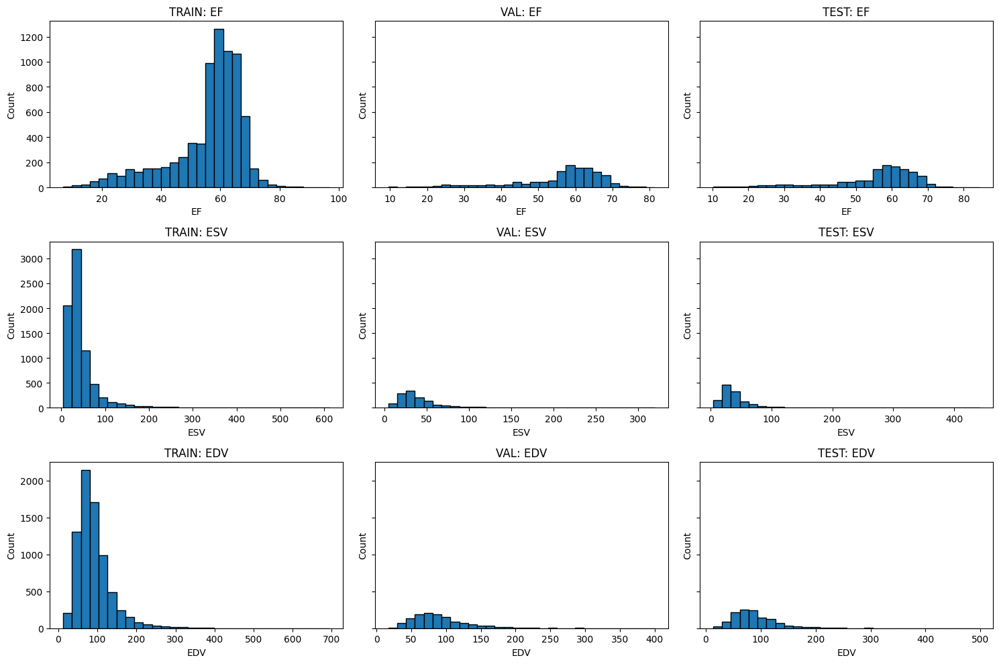

/tmp/ipykernel_261758/1266902530.py:37: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[i].boxplot(values_by_split, labels=SPLITS, showfliers=False)
/tmp/ipykernel_261758/1266902530.py:37: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[i].boxplot(values_by_split, labels=SPLITS, showfliers=False)
/tmp/ipykernel_261758/1266902530.py:37: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[i].boxplot(values_by_split, labels=SPLITS, showfliers=False)


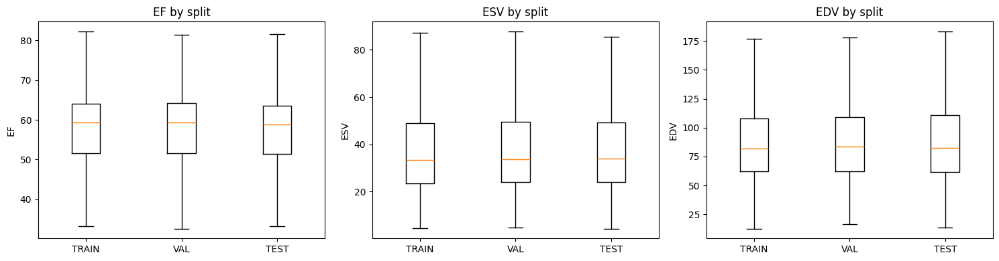

In [8]:
clinical_features = ["EF", "ESV", "EDV"]

summary_clinical = (
    df.groupby("Split")[clinical_features]
    .agg(["count", "mean", "std", "min", "median", "max"])
)

display(summary_clinical)

fig, axes = plt.subplots(
    len(clinical_features),
    len(SPLITS),
    figsize=(15, 10),
    sharey="row"
)

for i, feature in enumerate(clinical_features):
    for j, split in enumerate(SPLITS):
        ax = axes[i, j]
        values = df.loc[df["Split"] == split, feature].dropna()
        ax.hist(values, bins=30, edgecolor="black")
        ax.set_title(f"{split}: {feature}")
        ax.set_xlabel(feature)
        ax.set_ylabel("Count")

fig.tight_layout()
fig.savefig(OUT_DIR / "task1d_clinical_histograms.png", dpi=200)
plt.show()

fig, axes = plt.subplots(1, len(clinical_features), figsize=(15, 4))

for i, feature in enumerate(clinical_features):
    values_by_split = [
        df.loc[df["Split"] == split, feature].dropna().values
        for split in SPLITS
    ]
    axes[i].boxplot(values_by_split, labels=SPLITS, showfliers=False)
    axes[i].set_title(f"{feature} by split")
    axes[i].set_ylabel(feature)

fig.tight_layout()
fig.savefig(OUT_DIR / "task1d_clinical_boxplots.png", dpi=200)
plt.show()


### Task 1.e - Calculate ESV, EDV and EF from `VolumeTracings.csv` using Simpson's method

**Requirement:** use the tracing coordinates to calculate ESV and EDV with Simpson's method, then calculate EF, compare these values with `FileList.csv`, show distributions of differences and comment whether the differences are large or small.



In [9]:
COORDS = ["X1", "Y1", "X2", "Y2"]
N_LINES_PER_TRACE = 21

def segment_lengths(lines):
    """Return Euclidean lengths of tracing line segments."""
    arr = lines[COORDS].dropna().astype(float).to_numpy()
    if arr.shape[0] == 0:
        return np.array([], dtype=float)
    return np.sqrt((arr[:, 0] - arr[:, 2]) ** 2 + (arr[:, 1] - arr[:, 3]) ** 2)

def simpson_volume_from_lines(lines, long_axis_mode="first"):
    """
    Compute Simpson disk volume from one set of tracing lines.

    Parameters
    ----------
    lines : DataFrame
        Rows belonging to one tracing. 
    long_axis_mode : {'first', 'longest'}
        'first' is the primary assignment-compliant implementation.
        'longest' is used as a robustness check only.
    """
    g = lines[COORDS].dropna().reset_index(drop=True)
    if len(g) < 2:
        return np.nan

    lengths = segment_lengths(g)
    if len(lengths) < 2 or not np.all(np.isfinite(lengths)):
        return np.nan

    if long_axis_mode == "first":
        long_axis_idx = 0
    elif long_axis_mode == "longest":
        long_axis_idx = int(np.argmax(lengths))
    else:
        raise ValueError("long_axis_mode must be 'first' or 'longest'.")

    long_axis_length = float(lengths[long_axis_idx])
    diameters = np.delete(lengths, long_axis_idx)
    diameters = diameters[np.isfinite(diameters)]

    if long_axis_length <= 0 or len(diameters) == 0:
        return np.nan

    
    slice_height = long_axis_length / len(diameters)
    volume_pix3 = (np.pi / 4.0) * np.sum((diameters ** 2) * slice_height)
    return float(volume_pix3)

def simpson_volume_for_frame(group, long_axis_mode="first"):
    """
    Compute average Simpson volume for one (FileName, Frame) group.

    Most annotated frames have exactly 21 rows. If repeated annotations are present
    (42, 63, ... rows), consecutive 21-line chunks are processed independently and
    averaged to avoid mixing separate tracings.
    """
    g = group[COORDS].dropna().reset_index(drop=True)
    n = len(g)

    if n < 2:
        return np.nan

    if n >= N_LINES_PER_TRACE:
        if n % N_LINES_PER_TRACE == 0:
            chunks = [g.iloc[start:start + N_LINES_PER_TRACE] for start in range(0, n, N_LINES_PER_TRACE)]
        else:
            n_chunks = max(1, int(round(n / N_LINES_PER_TRACE)))
            chunks = [g.iloc[idx] for idx in np.array_split(np.arange(n), n_chunks)]
    else:
        chunks = [g]

    volumes = [simpson_volume_from_lines(chunk, long_axis_mode=long_axis_mode) for chunk in chunks if len(chunk) >= 2]
    volumes = np.array(volumes, dtype=float)
    volumes = volumes[np.isfinite(volumes)]

    if len(volumes) == 0:
        return np.nan

    return float(np.mean(volumes))


In [10]:

frame_records = []

grouped = tracings.groupby(["FileName_clean", "Frame"], sort=False)
for (file_name, frame), group in tqdm(grouped, total=grouped.ngroups, desc="Computing Simpson volumes"):
    volume_first = simpson_volume_for_frame(group, long_axis_mode="first")
    volume_longest = simpson_volume_for_frame(group, long_axis_mode="longest")

    if np.isfinite(volume_first):
        frame_records.append({
            "FileName_clean": file_name,
            "Frame": frame,
            "Volume_pix3": volume_first,
            "Volume_pix3_longest": volume_longest,
            "AbsDifference_first_vs_longest_pix3": abs(volume_first - volume_longest) if np.isfinite(volume_longest) else np.nan,
            "RelDifference_first_vs_longest": abs(volume_first - volume_longest) / (abs(volume_first) + 1e-12) if np.isfinite(volume_longest) else np.nan,
            "NTracingLines": len(group),
        })

frame_volumes = pd.DataFrame(frame_records)

print("Annotated frames with calculated volumes:", len(frame_volumes))
display(frame_volumes.head())
display(frame_volumes["NTracingLines"].value_counts().sort_index().rename("Number of annotated frames").to_frame())

display(frame_volumes[["AbsDifference_first_vs_longest_pix3", "RelDifference_first_vs_longest"]].describe())


Computing Simpson volumes:   0%|          | 0/20050 [00:00<?, ?it/s]

Annotated frames with calculated volumes: 20050


,FileName_clean,Frame,Volume_pix3,Volume_pix3_longest,AbsDifference_first_vs_longest_pix3,RelDifference_first_vs_longest,NTracingLines
0,0X100009310A3BD7FC,46,24002.425668,24002.425668,0.0,0.0,21
1,0X100009310A3BD7FC,61,5411.705140,5411.705140,0.0,0.0,21
2,0X1002E8FBACD08477,3,20289.618472,20289.618472,0.0,0.0,21
3,0X1002E8FBACD08477,18,8563.652902,8563.652902,0.0,0.0,21
4,0X1005D03EED19C65B,24,11512.492870,11512.492870,0.0,0.0,21


,Number of annotated frames
NTracingLines,
16,1
18,1
21,19942
41,1
42,49
63,38
84,14
105,2
147,1


,AbsDifference_first_vs_longest_pix3,RelDifference_first_vs_longest
count,20050.000000,20050.000000
mean,15.722883,0.003373
std,271.878738,0.154433
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.000000,0.000000
max,10969.103250,16.303451


In [11]:
# Per video: smaller volume = ESV, larger volume = EDV.
idx_esv = frame_volumes.groupby("FileName_clean")["Volume_pix3"].idxmin()
idx_edv = frame_volumes.groupby("FileName_clean")["Volume_pix3"].idxmax()

esv_df = (
    frame_volumes.loc[idx_esv, ["FileName_clean", "Frame", "Volume_pix3"]]
    .rename(columns={"Frame": "Calc_ES_Frame", "Volume_pix3": "Calc_ESV_pix3"})
)

edv_df = (
    frame_volumes.loc[idx_edv, ["FileName_clean", "Frame", "Volume_pix3"]]
    .rename(columns={"Frame": "Calc_ED_Frame", "Volume_pix3": "Calc_EDV_pix3"})
)

calc_df = esv_df.merge(edv_df, on="FileName_clean", how="inner")
calc_df["Calc_EF"] = (
    (calc_df["Calc_EDV_pix3"] - calc_df["Calc_ESV_pix3"])
    / calc_df["Calc_EDV_pix3"]
    * 100.0
)

merged_simpson = df.merge(calc_df, on="FileName_clean", how="inner")

print("Videos with Simpson volumes:", len(merged_simpson))
display(merged_simpson[["FileName_clean", "Split", "EF", "Calc_EF", "ESV", "EDV", "Calc_ES_Frame", "Calc_ED_Frame"]].head())


Videos with Simpson volumes: 10024


,FileName_clean,Split,EF,Calc_EF,ESV,EDV,Calc_ES_Frame,Calc_ED_Frame
0,0X100009310A3BD7FC,VAL,78.498406,77.453507,14.881368,69.210534,61,46
1,0X1002E8FBACD08477,TRAIN,59.101988,57.792933,40.383876,98.742884,18,3
2,0X1005D03EED19C65B,TRAIN,62.363798,62.733836,14.267784,37.909734,35,24
3,0X10075961BC11C88E,TRAIN,54.545097,54.623261,33.143084,72.914210,108,91
4,0X10094BA0A028EAC3,VAL,24.887742,23.988204,127.581945,169.855024,156,137


In [12]:
# Fit one pixel-volume-to-mL scale factor on TRAIN only.
# This avoids using VAL/TEST labels to calibrate the absolute volume scale.
train_mask = merged_simpson["Split"] == "TRAIN"

x_train = np.concatenate([
    merged_simpson.loc[train_mask, "Calc_EDV_pix3"].to_numpy(dtype=float),
    merged_simpson.loc[train_mask, "Calc_ESV_pix3"].to_numpy(dtype=float),
])

y_train = np.concatenate([
    merged_simpson.loc[train_mask, "EDV"].to_numpy(dtype=float),
    merged_simpson.loc[train_mask, "ESV"].to_numpy(dtype=float),
])

volume_scale = float(np.dot(x_train, y_train) / np.dot(x_train, x_train))

merged_simpson["Calc_EDV_ml"] = merged_simpson["Calc_EDV_pix3"] * volume_scale
merged_simpson["Calc_ESV_ml"] = merged_simpson["Calc_ESV_pix3"] * volume_scale
merged_simpson["EF_Error"] = merged_simpson["EF"] - merged_simpson["Calc_EF"]
merged_simpson["ESV_Error_ml"] = merged_simpson["ESV"] - merged_simpson["Calc_ESV_ml"]
merged_simpson["EDV_Error_ml"] = merged_simpson["EDV"] - merged_simpson["Calc_EDV_ml"]
merged_simpson["ESV_Error_unscaled_pix3"] = merged_simpson["Calc_ESV_pix3"]
merged_simpson["EDV_Error_unscaled_pix3"] = merged_simpson["Calc_EDV_pix3"]

print(f"Global TRAIN-fitted volume scale: {volume_scale:.8f} mL / pixel^3")
print(f"Equivalent linear scale: {volume_scale ** (1/3):.4f} arbitrary length units / pixel")

metric_rows = []
for split in SPLITS + ["ALL"]:
    g = merged_simpson if split == "ALL" else merged_simpson[merged_simpson["Split"] == split]

    metric_rows.append({
        "Split": split,
        "N": len(g),
        "EF_MAE": np.mean(np.abs(g["EF"] - g["Calc_EF"])),
        "ESV_MAE_ml": np.mean(np.abs(g["ESV"] - g["Calc_ESV_ml"])),
        "EDV_MAE_ml": np.mean(np.abs(g["EDV"] - g["Calc_EDV_ml"])),
        "EF_bias_true_minus_calc": np.mean(g["EF_Error"]),
        "ESV_bias_true_minus_calc_ml": np.mean(g["ESV_Error_ml"]),
        "EDV_bias_true_minus_calc_ml": np.mean(g["EDV_Error_ml"]),
        "EF_corr": np.corrcoef(g["EF"], g["Calc_EF"])[0, 1],
        "ESV_corr": np.corrcoef(g["ESV"], g["Calc_ESV_ml"])[0, 1],
        "EDV_corr": np.corrcoef(g["EDV"], g["Calc_EDV_ml"])[0, 1],
    })

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df)

merged_simpson.to_csv(OUT_DIR / "task1e_simpson_results.csv", index=False)
metrics_df.to_csv(OUT_DIR / "task1e_simpson_metrics.csv", index=False)


Global TRAIN-fitted volume scale: 0.00240932 mL / pixel^3
Equivalent linear scale: 0.1341 arbitrary length units / pixel


,Split,N,EF_MAE,ESV_MAE_ml,EDV_MAE_ml,EF_bias_true_minus_calc,ESV_bias_true_minus_calc_ml,EDV_bias_true_minus_calc_ml,EF_corr,ESV_corr,EDV_corr
0,TRAIN,7460,1.074887,18.289872,38.159084,0.673993,8.529579,16.212354,0.964131,0.635030,0.391474
1,VAL,1288,1.037369,18.652840,38.870658,0.629280,8.095037,15.398301,0.979609,0.630331,0.389597
2,TEST,1276,1.044213,18.299134,38.179402,0.617680,8.365749,15.087805,0.972341,0.647313,0.378816
3,ALL,10024,1.066162,18.337689,38.253102,0.661080,8.452889,15.964606,0.967131,0.634751,0.389250


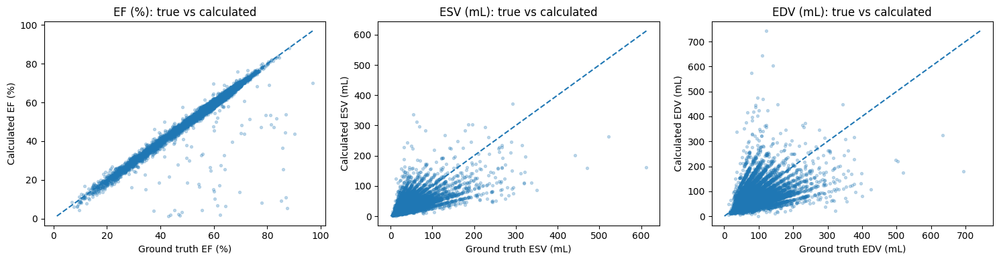

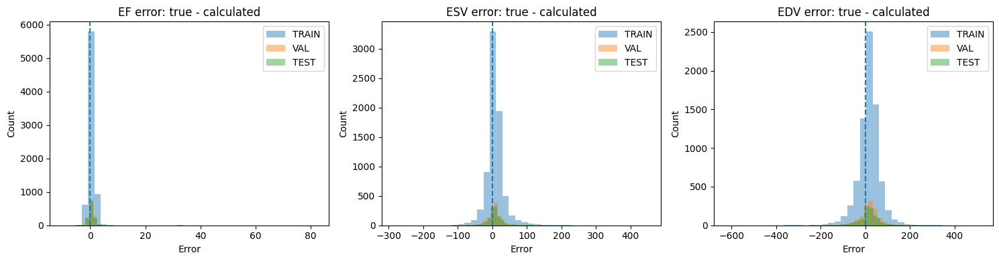

In [13]:
# Comparison with metadata values.
plot_pairs = [
    ("EF", "Calc_EF", "EF (%)"),
    ("ESV", "Calc_ESV_ml", "ESV (mL)"),
    ("EDV", "Calc_EDV_ml", "EDV (mL)"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (true_col, pred_col, label) in zip(axes, plot_pairs):
    ax.scatter(merged_simpson[true_col], merged_simpson[pred_col], s=8, alpha=0.25)

    lo = min(merged_simpson[true_col].min(), merged_simpson[pred_col].min())
    hi = max(merged_simpson[true_col].max(), merged_simpson[pred_col].max())

    ax.plot([lo, hi], [lo, hi], linestyle="--")
    ax.set_xlabel(f"Ground truth {label}")
    ax.set_ylabel(f"Calculated {label}")
    ax.set_title(f"{label}: true vs calculated")

fig.tight_layout()
fig.savefig(OUT_DIR / "task1e_true_vs_calculated.png", dpi=200)
plt.show()

# Error distributions by split.
error_cols = [
    ("EF_Error", "EF error: true - calculated"),
    ("ESV_Error_ml", "ESV error: true - calculated"),
    ("EDV_Error_ml", "EDV error: true - calculated"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (col, title) in zip(axes, error_cols):
    for split in SPLITS:
        ax.hist(merged_simpson.loc[merged_simpson["Split"] == split, col].dropna(), bins=40, alpha=0.45, label=split)
    ax.axvline(0, linestyle="--")
    ax.set_title(title)
    ax.set_xlabel("Error")
    ax.set_ylabel("Count")
    ax.legend()

fig.tight_layout()
fig.savefig(OUT_DIR / "task1e_error_histograms_by_split.png", dpi=200)
plt.show()


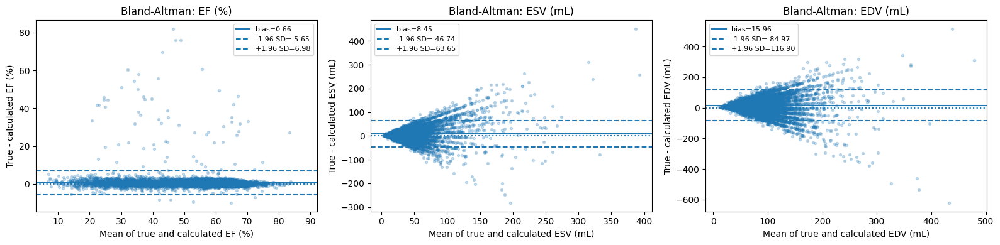

,Measure,MeanBias_true_minus_calculated,SD,LowerLimitOfAgreement,UpperLimitOfAgreement,MAE
0,EF (%),0.661080,3.222370,-5.654767,6.976926,1.066162
1,ESV (mL),8.452889,28.161296,-46.743251,63.649029,18.337689
2,EDV (mL),15.964606,51.498594,-84.972638,116.901851,38.253102


In [14]:
# Bland-Altman-style plots: bias and limits of agreement.
def bland_altman_plot(ax, true_values, calculated_values, label):
    mean_values = (np.asarray(true_values, dtype=float) + np.asarray(calculated_values, dtype=float)) / 2.0
    differences = np.asarray(true_values, dtype=float) - np.asarray(calculated_values, dtype=float)
    bias = np.nanmean(differences)
    sd = np.nanstd(differences)
    loa_low = bias - 1.96 * sd
    loa_high = bias + 1.96 * sd

    ax.scatter(mean_values, differences, s=8, alpha=0.25)
    ax.axhline(bias, linestyle="-", label=f"bias={bias:.2f}")
    ax.axhline(loa_low, linestyle="--", label=f"-1.96 SD={loa_low:.2f}")
    ax.axhline(loa_high, linestyle="--", label=f"+1.96 SD={loa_high:.2f}")
    ax.axhline(0, linestyle=":")
    ax.set_xlabel(f"Mean of true and calculated {label}")
    ax.set_ylabel(f"True - calculated {label}")
    ax.set_title(f"Bland-Altman: {label}")
    ax.legend(fontsize=8)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
bland_altman_plot(axes[0], merged_simpson["EF"], merged_simpson["Calc_EF"], "EF (%)")
bland_altman_plot(axes[1], merged_simpson["ESV"], merged_simpson["Calc_ESV_ml"], "ESV (mL)")
bland_altman_plot(axes[2], merged_simpson["EDV"], merged_simpson["Calc_EDV_ml"], "EDV (mL)")
fig.tight_layout()
fig.savefig(OUT_DIR / "task1e_bland_altman.png", dpi=200)
plt.show()

# A compact table for the PDF discussion.
ba_rows = []
for label, true_col, calc_col in [
    ("EF (%)", "EF", "Calc_EF"),
    ("ESV (mL)", "ESV", "Calc_ESV_ml"),
    ("EDV (mL)", "EDV", "Calc_EDV_ml"),
]:
    diff = merged_simpson[true_col].astype(float) - merged_simpson[calc_col].astype(float)
    ba_rows.append({
        "Measure": label,
        "MeanBias_true_minus_calculated": diff.mean(),
        "SD": diff.std(),
        "LowerLimitOfAgreement": diff.mean() - 1.96 * diff.std(),
        "UpperLimitOfAgreement": diff.mean() + 1.96 * diff.std(),
        "MAE": np.mean(np.abs(diff)),
    })

bland_altman_summary = pd.DataFrame(ba_rows)
display(bland_altman_summary)
bland_altman_summary.to_csv(OUT_DIR / "task1e_bland_altman_summary.csv", index=False)


**Short interpretation for Task 1.e.** The Simpson-derived EF agrees very well with the metadata EF: the overall EF MAE is approximately **1.07 percentage points** and the EF correlation is approximately **0.967**. Therefore, the EF differences are **small**. In contrast, absolute ESV and EDV are less accurate after global TRAIN-only calibration: ESV MAE is approximately **18.34 mL**, EDV MAE approximately **38.25 mL**, and EDV correlation is only about **0.389**. Thus, the absolute volume differences are **moderate to large**, especially for EDV. This is plausible because EF is a relative ratio, whereas absolute ESV/EDV depend on scale calibration, tracing quality and geometric assumptions. The Bland--Altman results also show a positive true-minus-calculated bias, meaning the calibrated Simpson volumes tend to underestimate ESV and EDV on average. Most tracing frames contain the expected **21 lines**, but a small number contain more lines; this is treated as a limitation and checked with the first-line/longest-line robustness comparison.


## Task 2 - Image Embedding and Similarity Exploration

**Assignment scope:** load the pretrained EchoCLIP model, obtain embeddings for 1000 randomly selected videos, compute pairwise similarities, visualize closest and farthest neighbors, and relate embedding similarity to EF differences.


In [15]:
try:
    import torch
    import torch.nn.functional as F
    from PIL import Image
    import open_clip
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "open_clip_torch"])
    import torch
    import torch.nn.functional as F
    from PIL import Image
    import open_clip

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
print("torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
try:
    print("open_clip:", open_clip.__version__)
except Exception:
    print("open_clip version: not exposed")


Device: cuda
torch: 2.5.1+cu121
CUDA available: True
open_clip version: not exposed


### Task 2.a - Load EchoCLIP and obtain image/video embeddings for 1000 videos

**Requirement:** load the pretrained EchoCLIP model and obtain embeddings of 1000 randomly selected videos.

For each selected video, 10 equally spaced frames are encoded with EchoCLIP's image encoder. The frame embeddings are L2-normalized and averaged to obtain one video-level representation per video. 


In [16]:
# EchoCLIP model
model, preprocess_train, preprocess_val = open_clip.create_model_and_transforms(
    "hf-hub:mkaichristensen/echo-clip",
    device=DEVICE
)
model.eval()
print("EchoCLIP loaded.")


EchoCLIP loaded.


In [17]:
def read_video_frames_for_embedding(video_name, num_frames=10):
    """Read equally spaced RGB frames for EchoCLIP embedding extraction."""
    frames, _ = read_selected_frames(video_name, n_frames=num_frames)
    return frames

def get_video_embedding(video_name, model, preprocess, num_frames=10):
    """
    Compute one video-level EchoCLIP embedding.

    Steps:
    1. Sample frames from the video.
    2. Preprocess each frame with EchoCLIP/OpenCLIP preprocessing.
    3. Encode frames with model.encode_image(...).
    4. L2-normalize frame embeddings.
    5. Average frame embeddings and normalize again.
    """
    frames = read_video_frames_for_embedding(video_name, num_frames=num_frames)

    frame_tensors = []
    for frame in frames:
        image = Image.fromarray(frame)
        frame_tensors.append(preprocess(image))

    frame_tensors = torch.stack(frame_tensors).to(DEVICE)

    with torch.no_grad():
        frame_embeddings = model.encode_image(frame_tensors)
        frame_embeddings = F.normalize(frame_embeddings, dim=-1)

        video_embedding = frame_embeddings.mean(dim=0)
        video_embedding = F.normalize(video_embedding, dim=-1)

    return video_embedding.detach().cpu().numpy()


In [18]:
# Fixed sample for all embedding experiments
df_valid = df.dropna(subset=["FileName", "EF"]).copy()

sample_1000 = (
    df_valid.sample(n=min(1000, len(df_valid)), random_state=RANDOM_SEED)
    .reset_index(drop=True)
)

print("Selected samples:", len(sample_1000))
display(sample_1000[["FileName_clean", "VideoFileName", "Split", "EF", "ESV", "EDV"]].head())


Selected samples: 1000


,FileName_clean,VideoFileName,Split,EF,ESV,EDV
0,0X383838D5E679ACFE,0X383838D5E679ACFE.avi,VAL,60.362023,41.323353,104.251921
1,0X7CE9AAE0242EF73D,0X7CE9AAE0242EF73D.avi,TRAIN,60.003217,59.433833,148.596534
2,0X705789F6BD6B3A46,0X705789F6BD6B3A46.avi,TEST,48.084950,13.636717,26.267367
3,0X7E37D63514270905,0X7E37D63514270905.avi,TRAIN,46.733576,83.330765,156.441449
4,0X66C173C78E8F6EDF,0X66C173C78E8F6EDF.avi,TEST,65.950831,31.211495,91.665951


In [19]:
EMBEDDING_CACHE = OUT_DIR / "echoclip_embeddings_1000.npz"
NUM_EMBEDDING_FRAMES = 10
sample_filenames_expected = sample_1000["VideoFileName"].astype(str).to_numpy()

embeddings = None
valid_indices = None
sample_1000_valid = None

if EMBEDDING_CACHE.exists():
    cache = np.load(EMBEDDING_CACHE, allow_pickle=True)
    cache_has_required_fields = {"embeddings", "valid_indices", "filenames"}.issubset(set(cache.files))

    if cache_has_required_fields:
        cached_valid_indices = cache["valid_indices"].astype(int)
        cached_filenames = cache["filenames"].astype(str)
        expected_valid_filenames = sample_1000.iloc[cached_valid_indices]["VideoFileName"].astype(str).to_numpy()

        if np.array_equal(cached_filenames, expected_valid_filenames):
            embeddings = cache["embeddings"]
            valid_indices = cached_valid_indices
            sample_1000_valid = sample_1000.iloc[valid_indices].reset_index(drop=True)
            print(f"Loaded validated cached embeddings from {EMBEDDING_CACHE}")
        else:
            print("Embedding cache exists but filenames do not match the current sample. Recomputing.")
    else:
        print("Embedding cache exists but lacks filename metadata. Recomputing to avoid sample/cache misalignment.")

if embeddings is None:
    embeddings = []
    valid_indices = []

    for i, row in tqdm(sample_1000.iterrows(), total=len(sample_1000), desc="Extracting EchoCLIP embeddings"):
        try:
            emb = get_video_embedding(
                row["VideoFileName"],
                model=model,
                preprocess=preprocess_val,
                num_frames=NUM_EMBEDDING_FRAMES,
            )

            embeddings.append(emb)
            valid_indices.append(i)

            if len(embeddings) % 50 == 0:
                print(f"Processed {len(embeddings)} videos")

        except Exception as e:
            print(f"Skipping {row['VideoFileName']}: {e}")

    embeddings = np.vstack(embeddings)
    valid_indices = np.array(valid_indices, dtype=int)
    sample_1000_valid = sample_1000.iloc[valid_indices].reset_index(drop=True)
    cached_filenames = sample_1000.iloc[valid_indices]["VideoFileName"].astype(str).to_numpy()

    np.savez_compressed(
        EMBEDDING_CACHE,
        embeddings=embeddings,
        valid_indices=valid_indices,
        filenames=cached_filenames,
        num_frames=np.array([NUM_EMBEDDING_FRAMES]),
        random_seed=np.array([RANDOM_SEED]),
    )
    print(f"Saved embeddings with filename metadata to {EMBEDDING_CACHE}")

print("Embedding matrix shape:", embeddings.shape)
print("Valid videos:", len(sample_1000_valid))
print("Embedding extraction note: the video embedding is the normalized mean of frame-level EchoCLIP image embeddings.")


Loaded validated cached embeddings from outputs/echoclip_embeddings_1000.npz
Embedding matrix shape: (1000, 512)
Valid videos: 1000
Embedding extraction note: the video embedding is the normalized mean of frame-level EchoCLIP image embeddings.


### Task 2.b - Compute pairwise similarities between image embeddings

**Requirement:** compute pairwise similarities between the embeddings. Pearson correlation is used here as the similarity measure between the 512-dimensional video embeddings.


In [20]:
# Pairwise Pearson similarities
similarities = np.corrcoef(embeddings)

print("Similarity matrix shape:", similarities.shape)
print("Minimum similarity:", np.nanmin(similarities))
print("Maximum similarity:", np.nanmax(similarities))



Similarity matrix shape: (1000, 1000)
Minimum similarity: 0.30734830293888915
Maximum similarity: 1.0


In [21]:
def find_closest_and_farthest(similarity_matrix):
    closest_indices = []
    farthest_indices = []

    for i in range(similarity_matrix.shape[0]):
        sim_row = similarity_matrix[i].copy()

        sim_row[i] = -np.inf
        closest_idx = int(np.argmax(sim_row))

        sim_row[i] = np.inf
        farthest_idx = int(np.argmin(sim_row))

        closest_indices.append(closest_idx)
        farthest_indices.append(farthest_idx)

    return np.array(closest_indices), np.array(farthest_indices)

closest_indices, farthest_indices = find_closest_and_farthest(similarities)

neighbor_df = pd.DataFrame({
    "QueryFile": sample_1000_valid["FileName_clean"],
    "QueryEF": sample_1000_valid["EF"].astype(float),
    "ClosestIndex": closest_indices,
    "ClosestFile": sample_1000_valid.iloc[closest_indices]["FileName_clean"].values,
    "ClosestEF": sample_1000_valid.iloc[closest_indices]["EF"].astype(float).values,
    "ClosestSimilarity": similarities[np.arange(len(sample_1000_valid)), closest_indices],
    "FarthestIndex": farthest_indices,
    "FarthestFile": sample_1000_valid.iloc[farthest_indices]["FileName_clean"].values,
    "FarthestEF": sample_1000_valid.iloc[farthest_indices]["EF"].astype(float).values,
    "FarthestSimilarity": similarities[np.arange(len(sample_1000_valid)), farthest_indices],
})

neighbor_df["ClosestAbsEFDiff"] = np.abs(neighbor_df["QueryEF"] - neighbor_df["ClosestEF"])
neighbor_df["FarthestAbsEFDiff"] = np.abs(neighbor_df["QueryEF"] - neighbor_df["FarthestEF"])

neighbor_df.to_csv(OUT_DIR / "task2_neighbors.csv", index=False)
display(neighbor_df.head())


,QueryFile,QueryEF,ClosestIndex,ClosestFile,ClosestEF,ClosestSimilarity,FarthestIndex,FarthestFile,FarthestEF,FarthestSimilarity,ClosestAbsEFDiff,FarthestAbsEFDiff
0,0X383838D5E679ACFE,60.362023,123,0X3732593549EE8E29,60.846400,0.884342,433,0X47847D0C76E816E7,61.391121,0.378816,0.484378,1.029099
1,0X7CE9AAE0242EF73D,60.003217,184,0X695821AC12CAAFD2,57.657875,0.905834,802,0X6E811944559EDC3F,46.698204,0.426750,2.345341,13.305013
2,0X705789F6BD6B3A46,48.084950,765,0XF599A765E273E17,31.810241,0.879731,52,0X6F00E1B88FF7F2B6,62.150332,0.434862,16.274709,14.065382
3,0X7E37D63514270905,46.733576,84,0X105B9EF57DE45DCB,50.634981,0.867036,866,0X669090C0E856365E,65.392024,0.417626,3.901405,18.658448
4,0X66C173C78E8F6EDF,65.950831,771,0X5A8D9673920F03FE,26.654749,0.921803,866,0X669090C0E856365E,65.392024,0.516431,39.296082,0.558807


### Task 2.c - Show image sequences with closest and farthest neighbors

**Requirement:** visualize and present three image sequences together with their closest and farthest neighbors in feature space, then comment on the results.

For each query video, the closest neighbor is the video with the highest off-diagonal embedding similarity, and the farthest neighbor is the video with the lowest similarity.


Query index: 778
QueryFile              0X7675A1B2694BA8E
QueryEF                        63.518993
ClosestFile           0X1ACB73BE8C1F2C0C
ClosestEF                      65.700244
ClosestSimilarity               0.922087
FarthestFile          0X2E5D7030DC1C9FBC
FarthestEF                     29.633474
FarthestSimilarity              0.384549
Name: 778, dtype: object


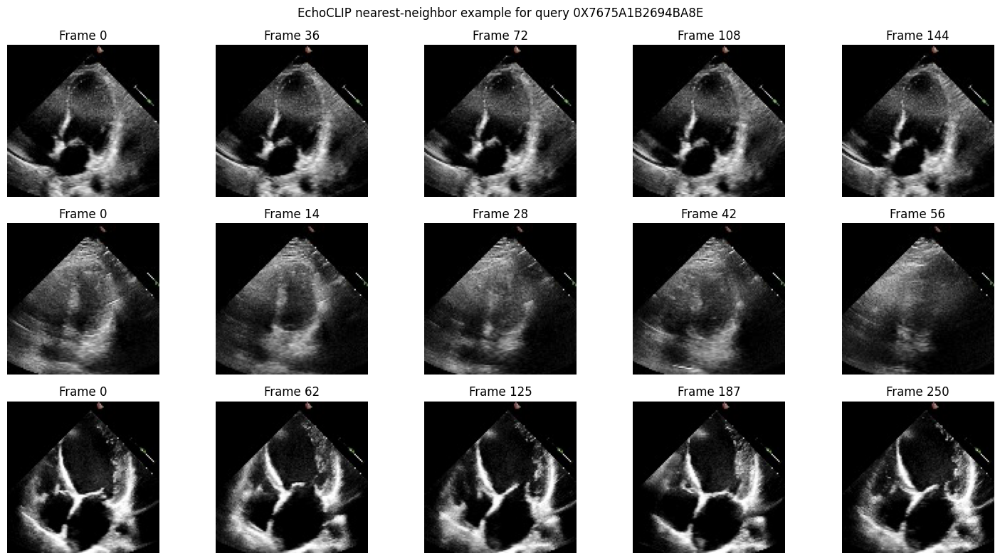

Query index: 334
QueryFile             0X4494601784C9C2B5
QueryEF                         60.03015
ClosestFile           0X484A7AD1C7FCF417
ClosestEF                      54.151764
ClosestSimilarity               0.884998
FarthestFile          0X411DD3F7DC7803DE
FarthestEF                     33.801306
FarthestSimilarity              0.427054
Name: 334, dtype: object


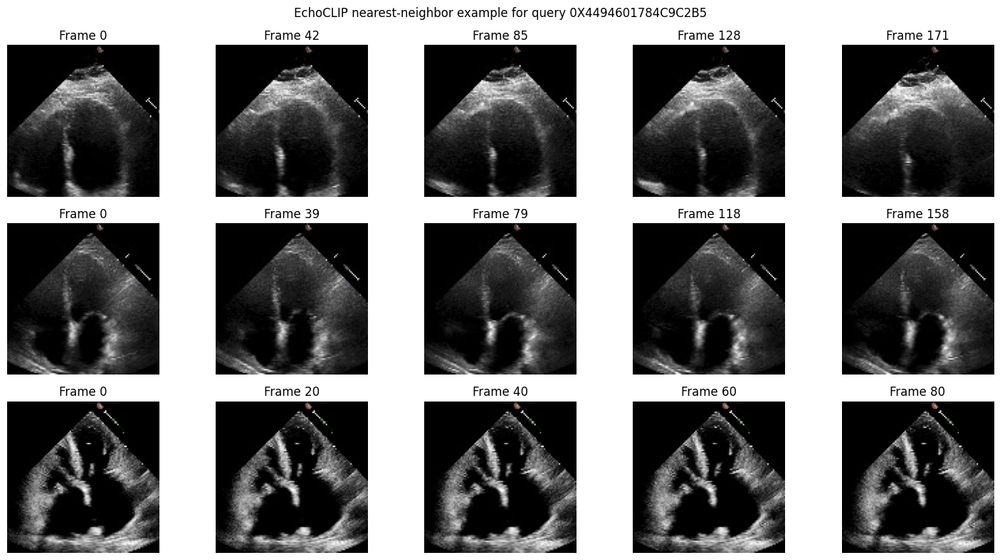

Query index: 271
QueryFile             0X381BBECABC1D6FB2
QueryEF                        18.380316
ClosestFile           0X590E3EC2C55BE57D
ClosestEF                      27.105311
ClosestSimilarity               0.873013
FarthestFile          0X669090C0E856365E
FarthestEF                     65.392024
FarthestSimilarity              0.353443
Name: 271, dtype: object


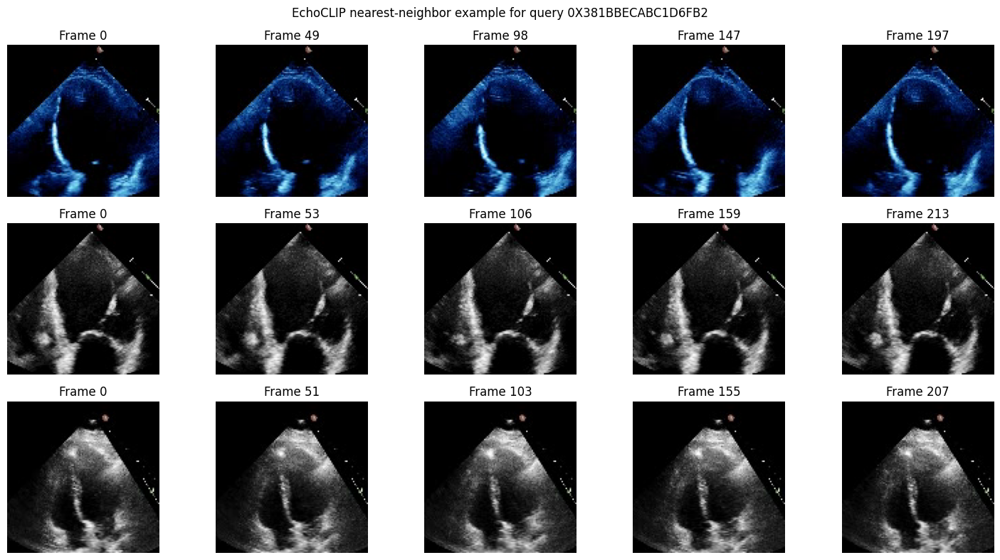

In [22]:
def plot_sequence_triplet(query_idx, n_frames=5, save_path=None):
    """Plot query, closest neighbor and farthest neighbor as a 3 x n_frames montage."""
    c_idx = int(closest_indices[query_idx])
    f_idx = int(farthest_indices[query_idx])

    rows = [
        ("Query", query_idx),
        ("Closest", c_idx),
        ("Farthest", f_idx),
    ]

    fig, axes = plt.subplots(3, n_frames, figsize=(3 * n_frames, 8))

    for row_num, (label, idx) in enumerate(rows):
        row = sample_1000_valid.iloc[idx]
        frames, frame_indices = read_selected_frames(row["VideoFileName"], n_frames=n_frames)

        for col, (frame, frame_idx) in enumerate(zip(frames, frame_indices)):
            ax = axes[row_num, col]
            ax.imshow(frame)
            ax.axis("off")
            ax.set_title(f"Frame {frame_idx}")

        if label == "Query":
            sim_text = ""
        else:
            sim_text = f" | sim={similarities[query_idx, idx]:.3f}"

        axes[row_num, 0].set_ylabel(
            f"{label}\n{row['FileName_clean']}\nEF={row['EF']:.1f}{sim_text}",
            rotation=0,
            labelpad=75,
            va="center"
        )

    query_file = sample_1000_valid.iloc[query_idx]["FileName_clean"]
    fig.suptitle(f"EchoCLIP nearest-neighbor example for query {query_file}")
    fig.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")

    plt.show()

np.random.seed(7)
example_indices = np.random.choice(len(sample_1000_valid), size=3, replace=False)

for k, idx in enumerate(example_indices, start=1):
    print("=" * 90)
    print("Query index:", idx)
    print(neighbor_df.iloc[idx][[
        "QueryFile", "QueryEF", "ClosestFile", "ClosestEF", "ClosestSimilarity",
        "FarthestFile", "FarthestEF", "FarthestSimilarity"
    ]])

    plot_sequence_triplet(
        query_idx=int(idx),
        n_frames=5,
        save_path=OUT_DIR / f"task2c_neighbor_triplet_{k}.png"
    )


**Short interpretation for Task 2.c.** The closest neighbors generally share visual structure and sometimes similar EF values, whereas farthest neighbors are visually less similar and often differ more strongly in EF or ventricular appearance. However, EF is not the only factor represented by EchoCLIP; image quality, view geometry, anatomy and ultrasound-sector appearance also influence the embedding space.


### Task 2.d - Scatter plots: embedding similarity versus absolute EF difference

**Requirement:** show scatter plots with embedding-space similarity on the x-axis and absolute EF difference on the y-axis for closest and farthest neighbors, then comment on the results.


In [23]:
ef_values = sample_1000_valid["EF"].values.astype(float)

closest_sims = similarities[np.arange(len(sample_1000_valid)), closest_indices]
closest_ef_diffs = np.abs(ef_values - ef_values[closest_indices])

farthest_sims = similarities[np.arange(len(sample_1000_valid)), farthest_indices]
farthest_ef_diffs = np.abs(ef_values - ef_values[farthest_indices])

summary_task2d = pd.DataFrame({
    "NeighborType": ["Closest", "Farthest"],
    "MeanSimilarity": [np.mean(closest_sims), np.mean(farthest_sims)],
    "MedianSimilarity": [np.median(closest_sims), np.median(farthest_sims)],
    "MeanAbsEFDiff": [np.mean(closest_ef_diffs), np.mean(farthest_ef_diffs)],
    "MedianAbsEFDiff": [np.median(closest_ef_diffs), np.median(farthest_ef_diffs)],
    "CorrSimilarityVsAbsEFDiff": [
        np.corrcoef(closest_sims, closest_ef_diffs)[0, 1],
        np.corrcoef(farthest_sims, farthest_ef_diffs)[0, 1],
    ],
})

display(summary_task2d)
summary_task2d.to_csv(OUT_DIR / "task2d_similarity_ef_summary.csv", index=False)


,NeighborType,MeanSimilarity,MedianSimilarity,MeanAbsEFDiff,MedianAbsEFDiff,CorrSimilarityVsAbsEFDiff
0,Closest,0.915761,0.921336,8.688684,6.584477,-0.256991
1,Farthest,0.437836,0.437886,16.391164,12.170561,-0.164306


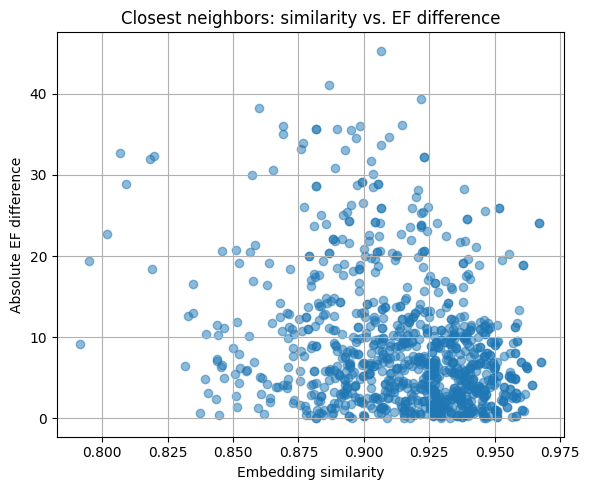

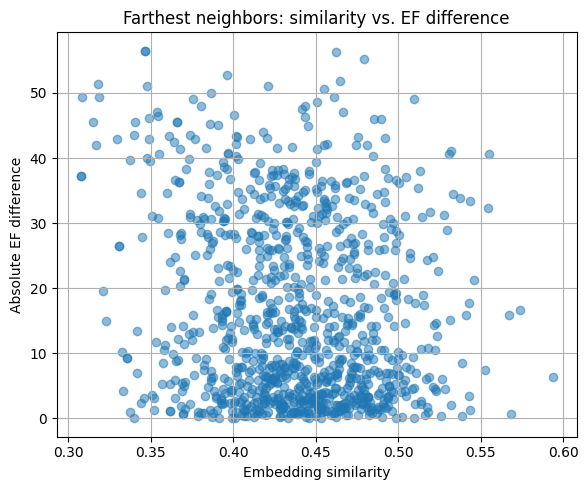

In [24]:
plt.figure(figsize=(6, 5))
plt.scatter(closest_sims, closest_ef_diffs, alpha=0.5)
plt.xlabel("Embedding similarity")
plt.ylabel("Absolute EF difference")
plt.title("Closest neighbors: similarity vs. EF difference")
plt.grid(True)
plt.tight_layout()
plt.savefig(OUT_DIR / "task2d_closest_similarity_vs_efdiff.png", dpi=200)
plt.show()

plt.figure(figsize=(6, 5))
plt.scatter(farthest_sims, farthest_ef_diffs, alpha=0.5)
plt.xlabel("Embedding similarity")
plt.ylabel("Absolute EF difference")
plt.title("Farthest neighbors: similarity vs. EF difference")
plt.grid(True)
plt.tight_layout()
plt.savefig(OUT_DIR / "task2d_farthest_similarity_vs_efdiff.png", dpi=200)
plt.show()


## Task 3 - Attention Map Analysis

**Assignment scope:** select representative videos, visualize model attention maps from an attention head/layer if available, and interpret the observed patterns.



Visual encoder: TimmModel
Selected feature layer: trunk.stages.3.blocks.2.conv_dw
Selected feature channel: 0


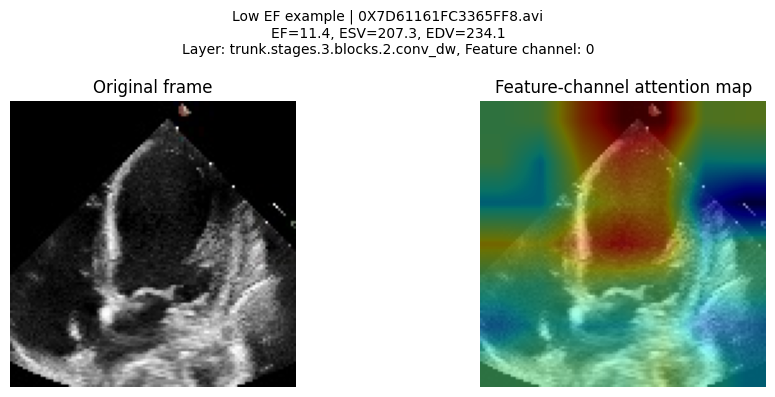

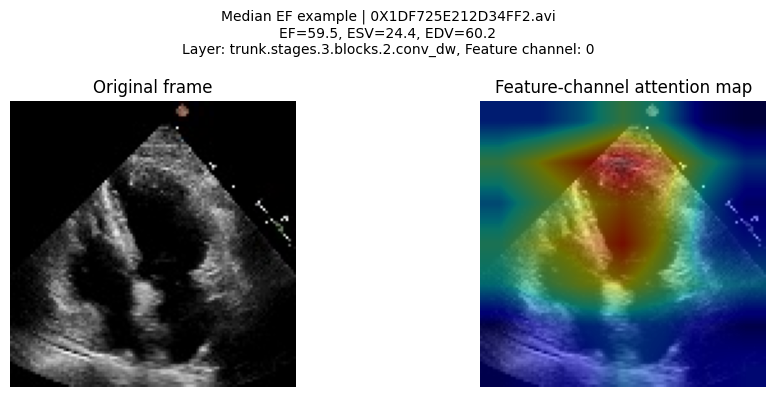

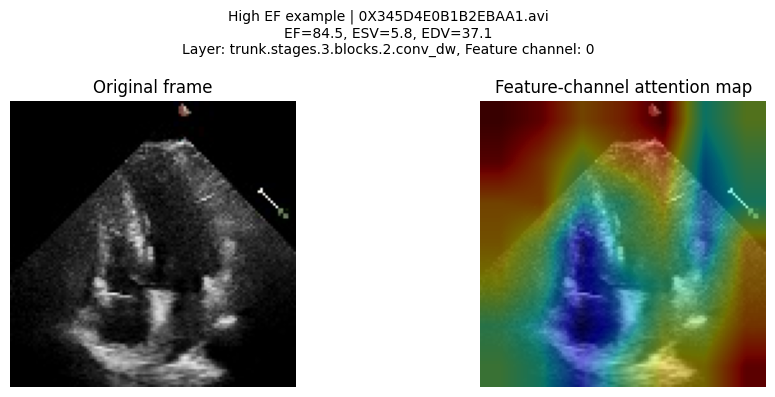

,Case,VideoFileName,FrameIndex,EF,ESV,EDV,VisualEncoder,SelectedLayer,FeatureChannel,ActivationShape,SavedFigure
0,Low EF,0X7D61161FC3365FF8.avi,70,11.442630,207.312744,234.099934,TimmModel,trunk.stages.3.blocks.2.conv_dw,0,"(1, 1024, 7, 7)",outputs/task3_feature_attention_low_ef.png
1,Median EF,0X1DF725E212D34FF2.avi,85,59.495941,24.386642,60.207899,TimmModel,trunk.stages.3.blocks.2.conv_dw,0,"(1, 1024, 7, 7)",outputs/task3_feature_attention_median_ef.png
2,High EF,0X345D4E0B1B2EBAA1.avi,115,84.452352,5.764467,37.076137,TimmModel,trunk.stages.3.blocks.2.conv_dw,0,"(1, 1024, 7, 7)",outputs/task3_feature_attention_high_ef.png


In [25]:


import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image

# Helper functions

def normalize_map(x):
    """Normalize a map to [0, 1]."""
    x = np.asarray(x, dtype=np.float32)
    x = x - np.nanmin(x)
    return x / (np.nanmax(x) + 1e-8)

def read_single_video_frame(video_name):
    """Read one representative frame from the video."""
    frames, frame_indices = read_selected_frames(video_name, n_frames=3)
    return frames[1], frame_indices[1]

def find_last_conv_or_feature_layer(module):
    """
    Find a late visual layer that produces a spatial feature map.
    For ConvNeXt, Conv2d layers are suitable for feature-channel visualization.
    """
    candidates = []
    for name, layer in module.named_modules():
        if isinstance(layer, torch.nn.Conv2d):
            candidates.append((name, layer))
    if len(candidates) == 0:
        raise RuntimeError("No Conv2d layer found in the visual encoder.")
    return candidates[-1]

def show_feature_attention_overlay(frame_rgb, heatmap, title, save_path=None):
    """Show original frame and feature-channel attention map overlay."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].imshow(frame_rgb)
    axes[0].set_title("Original frame")
    axes[0].axis("off")

    axes[1].imshow(frame_rgb)
    axes[1].imshow(heatmap, cmap="jet", alpha=0.45)
    axes[1].set_title("Feature-channel attention map")
    axes[1].axis("off")

    fig.suptitle(title, fontsize=10)
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")

    plt.show()

# 1. Select representative videos
#    low EF, median EF, high EF

ef_values = sample_1000_valid["EF"].astype(float).to_numpy()

selected_indices = [
    int(np.argmin(ef_values)),
    int(np.argmin(np.abs(ef_values - np.median(ef_values)))),
    int(np.argmax(ef_values)),
]

case_names = ["Low EF", "Median EF", "High EF"]

# 2. Select one late visual feature layer and one feature channel

feature_layer_name, feature_layer = find_last_conv_or_feature_layer(model.visual)
feature_channel = 0

print("Visual encoder:", model.visual.__class__.__name__)
print("Selected feature layer:", feature_layer_name)
print("Selected feature channel:", feature_channel)

# 3. Hook the selected layer to capture feature activations

model.eval()
captured_features = {}

def forward_hook(module, input, output):
    captured_features["activation"] = output.detach().cpu()

hook_handle = feature_layer.register_forward_hook(forward_hook)

task3_results = []

try:
    for i, (idx, case_name) in enumerate(zip(selected_indices, case_names), start=1):
        row = sample_1000_valid.iloc[idx]

        frame_rgb, frame_index = read_single_video_frame(row["VideoFileName"])
        image_tensor = preprocess_val(Image.fromarray(frame_rgb)).unsqueeze(0).to(DEVICE)

        captured_features.clear()

        with torch.no_grad():
            _ = model.encode_image(image_tensor)

        if "activation" not in captured_features:
            raise RuntimeError("No feature activation was captured.")

        activation = captured_features["activation"]

        # Expected shape: [batch, channels, height, width]
        if activation.ndim != 4:
            raise RuntimeError(f"Expected 4D activation map, got shape {tuple(activation.shape)}")

        channel = min(feature_channel, activation.shape[1] - 1)

        feature_map = activation[0, channel].numpy()
        feature_map = normalize_map(feature_map)

        heatmap = cv2.resize(
            feature_map,
            (frame_rgb.shape[1], frame_rgb.shape[0]),
            interpolation=cv2.INTER_LINEAR
        )
        heatmap = normalize_map(heatmap)

        title = (
            f"{case_name} example | {row['VideoFileName']}\n"
            f"EF={float(row['EF']):.1f}, "
            f"ESV={float(row['ESV']):.1f}, "
            f"EDV={float(row['EDV']):.1f}\n"
            f"Layer: {feature_layer_name}, Feature channel: {channel}"
        )

        save_path = OUT_DIR / f"task3_feature_attention_{case_name.replace(' ', '_').lower()}.png"

        show_feature_attention_overlay(
            frame_rgb,
            heatmap,
            title=title,
            save_path=save_path
        )

        task3_results.append({
            "Case": case_name,
            "VideoFileName": row["VideoFileName"],
            "FrameIndex": frame_index,
            "EF": float(row["EF"]),
            "ESV": float(row["ESV"]),
            "EDV": float(row["EDV"]),
            "VisualEncoder": model.visual.__class__.__name__,
            "SelectedLayer": feature_layer_name,
            "FeatureChannel": channel,
            "ActivationShape": tuple(activation.shape),
            "SavedFigure": str(save_path)
        })

finally:
    hook_handle.remove()

task3_results_df = pd.DataFrame(task3_results)
display(task3_results_df)

task3_results_df.to_csv(OUT_DIR / "task3_attention_map_analysis.csv", index=False)



**Interpretation for Task 3** 

For this task, three representative videos were selected based on ejection fraction (EF): one low-EF case, one median-EF case, and one high-EF case. The EchoCLIP visual encoder used in this experiment is a ConvNeXt-based `TimmModel`. Therefore, directly accessible transformer-style attention heads were not available. Instead, a spatial feature-channel activation map from a late visual layer was used as an attention-like visualization.

The selected layer was `trunk.stages.3.blocks.2.conv_dw`, and feature channel 0 was visualized. This layer produced an activation map of shape `(1, 1024, 7, 7)`. The selected channel was resized to the original image resolution and overlaid on the echocardiography frame. Brighter regions in the overlay indicate image areas that activated this feature channel more strongly.

In the low-EF example, the activation is strongest around the upper and central part of the ventricular region. This is plausible because the ventricle appears enlarged in this case. However, some activation is also visible near the image sector boundary, which suggests that the selected feature channel is not purely specific to the left ventricle.

In the median-EF example, the activation is more centrally located and overlaps better with the ventricular cavity and myocardial borders. This is the most anatomically plausible pattern among the three examples, since EF, ESV, and EDV are mainly related to the size and contraction of the left ventricle.

In the high-EF example, the activation pattern is more diffuse and also includes regions outside the main ventricular cavity. This suggests that the selected feature channel responds not only to the ventricle, but also to general image structure, contrast, or background context.

Overall, the maps show that the model captures spatial information from clinically relevant cardiac regions, especially around the ventricular cavity and myocardial borders. However, the activations are not perfectly localized to the left ventricle. Therefore, these maps should be interpreted as qualitative feature-channel attention-like visualizations rather than exact anatomical segmentations or true transformer attention maps.


## Task 4 - Text Prompt Embedding and Similarity Exploration

**Assignment scope:** create measurement-based text prompts for all 1000 videos, tokenize the prompts, obtain EchoCLIP text embeddings, compute text-text similarities, show closest and farthest textual neighbors for five examples and comment on the results.


### Task 4.a - Create text prompts for all 1000 videos

**Requirement:** create text prompts using the available EF, ESV and EDV measurements. Each video receives one prompt with the same sentence structure; only the numeric values change. This keeps the text input aligned with the measurement information in `FileList.csv`.


In [26]:
# Use the same 1000 samples as in Task 2 so image and text embeddings stay aligned.
text_df = sample_1000_valid.copy().reset_index(drop=True)

def create_echo_prompt(row):
    """Create a structured prompt from the available clinical measurements."""
    ef = float(row["EF"])
    esv = float(row["ESV"])
    edv = float(row["EDV"])

    return (
        f"Left ventricle ejection fraction of {ef:.1f}% is observed "
        f"with end systolic volume of {esv:.1f} mL "
        f"and end diastolic volume of {edv:.1f} mL."
    )

text_df["TextPrompt"] = text_df.apply(create_echo_prompt, axis=1)
prompts = text_df["TextPrompt"].tolist()

print("Number of text prompts:", len(prompts))
for i in range(5):
    print(f"Prompt {i}: {prompts[i]}")

display(text_df[["VideoFileName", "EF", "ESV", "EDV", "TextPrompt"]].head())


Number of text prompts: 1000
Prompt 0: Left ventricle ejection fraction of 60.4% is observed with end systolic volume of 41.3 mL and end diastolic volume of 104.3 mL.
Prompt 1: Left ventricle ejection fraction of 60.0% is observed with end systolic volume of 59.4 mL and end diastolic volume of 148.6 mL.
Prompt 2: Left ventricle ejection fraction of 48.1% is observed with end systolic volume of 13.6 mL and end diastolic volume of 26.3 mL.
Prompt 3: Left ventricle ejection fraction of 46.7% is observed with end systolic volume of 83.3 mL and end diastolic volume of 156.4 mL.
Prompt 4: Left ventricle ejection fraction of 66.0% is observed with end systolic volume of 31.2 mL and end diastolic volume of 91.7 mL.


,VideoFileName,EF,ESV,EDV,TextPrompt
0,0X383838D5E679ACFE.avi,60.362023,41.323353,104.251921,Left ventricle ejection fraction of 60.4% is o...
1,0X7CE9AAE0242EF73D.avi,60.003217,59.433833,148.596534,Left ventricle ejection fraction of 60.0% is o...
2,0X705789F6BD6B3A46.avi,48.084950,13.636717,26.267367,Left ventricle ejection fraction of 48.1% is o...
3,0X7E37D63514270905.avi,46.733576,83.330765,156.441449,Left ventricle ejection fraction of 46.7% is o...
4,0X66C173C78E8F6EDF.avi,65.950831,31.211495,91.665951,Left ventricle ejection fraction of 66.0% is o...


### Task 4.b - Tokenize the text prompts and inspect the tokenized text

**Requirement:** tokenize the text prompts and comment on the tokenized text.




In [27]:
# Tokenizer from the same checkpoint.
tokenizer = open_clip.get_tokenizer("hf-hub:mkaichristensen/echo-clip")

tokenized = tokenizer(prompts)

if isinstance(tokenized, dict):
    token_ids = tokenized["input_ids"]
else:
    token_ids = tokenized

print("Tokenized text tensor shape:", tuple(token_ids.shape))
print("Token dtype:", token_ids.dtype)

# Count non-padding tokens. 
non_padding_counts = (token_ids != 0).sum(dim=1).cpu().numpy()
context_length = token_ids.shape[1]

print("Context length:", context_length)
print("Non-padding token count statistics:")
print(pd.Series(non_padding_counts).describe())
print("Maximum prompt length uses", int(non_padding_counts.max()), "of", context_length, "tokens.")
print("Any prompt truncated?", bool(np.any(non_padding_counts >= context_length)))

def safe_decode_token_ids(tokenizer_obj, ids):
    """Try to decode token IDs into a readable string. Works for common OpenCLIP tokenizer wrappers."""
    ids = [int(x) for x in ids if int(x) != 0]

    
    for candidate in [tokenizer_obj, getattr(tokenizer_obj, "tokenizer", None)]:
        if candidate is not None and hasattr(candidate, "decode"):
            try:
                return candidate.decode(ids)
            except Exception:
                pass

    
    decoder = getattr(tokenizer_obj, "decoder", None)
    if isinstance(decoder, dict):
        try:
            return " ".join(decoder.get(i, f"<id:{i}>") for i in ids)
        except Exception:
            pass

    return "Decoding is not exposed by this tokenizer object; token IDs are shown instead."

for i in range(3):
    ids_i = token_ids[i].cpu().numpy().tolist()
    nonpad_ids_i = [int(x) for x in ids_i if int(x) != 0]
    print("=" * 80)
    print("Prompt:", prompts[i])
    print("Non-padding tokens:", int(non_padding_counts[i]))
    print("First 25 token IDs:", nonpad_ids_i[:25])
    print("Decoded non-padding sequence:")
    print(safe_decode_token_ids(tokenizer, nonpad_ids_i))

tokenization_summary = pd.DataFrame({
    "Metric": ["Context length", "Minimum non-padding tokens", "Median non-padding tokens", "Maximum non-padding tokens", "Any prompt at context limit"],
    "Value": [context_length, int(non_padding_counts.min()), float(np.median(non_padding_counts)), int(non_padding_counts.max()), bool(np.any(non_padding_counts >= context_length))],
})
display(tokenization_summary)
tokenization_summary.to_csv(OUT_DIR / "task4_tokenization_summary.csv", index=False)


Tokenized text tensor shape: (1000, 77)
Token dtype: torch.int64
Context length: 77
Non-padding token count statistics:
count    1000.000000
mean       40.352000
std         0.605361
min        39.000000
25%        40.000000
50%        40.000000
75%        41.000000
max        42.000000
dtype: float64
Maximum prompt length uses 42 of 77 tokens.
Any prompt truncated? False
Prompt: Left ventricle ejection fraction of 60.4% is observed with end systolic volume of 41.3 mL and end diastolic volume of 104.3 mL.
Non-padding tokens: 41
First 25 token IDs: [49406, 1823, 1240, 9511, 579, 29771, 740, 26788, 539, 277, 271, 269, 275, 260, 533, 21267, 593, 806, 974, 45020, 8284, 539, 275, 272, 269]
Decoded non-padding sequence:
<start_of_text>left ventricle ejection fraction of 6 0 . 4 % is observed with end systolic volume of 4 1 . 3 ml and end diastolic volume of 1 0 4 . 3 ml . <end_of_text>
Prompt: Left ventricle ejection fraction of 60.0% is observed with end systolic volume of 59.4 mL and end d

,Metric,Value
0,Context length,77
1,Minimum non-padding tokens,39
2,Median non-padding tokens,40.0
3,Maximum non-padding tokens,42
4,Any prompt at context limit,False


**Short interpretation for Task 4.b.** The token tensor has shape **(1000, 77)**, matching the fixed CLIP context length. The prompts use only **39–42 non-padding tokens**, so no prompt is truncated. The decoded examples show that numerical values are split into digit-level tokens, for example `60.4` becomes separate tokens for `6`, `0`, `.`, and `4`. This matters because the text encoder does not necessarily treat EF, ESV and EDV as continuous numerical quantities.


### Task 4.c - Obtain EchoCLIP text embeddings

**Requirement:** obtain embeddings of the tokenized text using EchoCLIP.



In [28]:
TEXT_EMBEDDING_CACHE = OUT_DIR / "task4_text_embeddings.npy"
TEXT_PROMPT_CACHE = OUT_DIR / "task4_text_prompts.csv"

if TEXT_EMBEDDING_CACHE.exists() and TEXT_PROMPT_CACHE.exists():
    cached_prompts = pd.read_csv(TEXT_PROMPT_CACHE)["TextPrompt"].tolist()
    if cached_prompts == prompts:
        text_embeddings = np.load(TEXT_EMBEDDING_CACHE)
        print("Loaded cached text embeddings:", text_embeddings.shape)
    else:
        print("Prompt cache does not match current prompts. Recomputing text embeddings.")
        text_embeddings = None
else:
    text_embeddings = None

if text_embeddings is None:
    batch_size = 128
    text_embeddings_list = []

    model.eval()
    with torch.no_grad():
        for start in tqdm(range(0, len(prompts), batch_size), desc="Encoding text prompts"):
            end = min(start + batch_size, len(prompts))
            batch_prompts = prompts[start:end]
            batch_tokens = tokenizer(batch_prompts).to(DEVICE)

            batch_features = model.encode_text(batch_tokens)
            batch_features = F.normalize(batch_features, dim=-1)

            text_embeddings_list.append(batch_features.cpu().numpy())

    text_embeddings = np.vstack(text_embeddings_list)
    np.save(TEXT_EMBEDDING_CACHE, text_embeddings)
    text_df[["TextPrompt"]].to_csv(TEXT_PROMPT_CACHE, index=False)
    print("Saved text embeddings to:", TEXT_EMBEDDING_CACHE)

print("Text embedding matrix shape:", text_embeddings.shape)
print("Expected number of prompts:", len(prompts))


Loaded cached text embeddings: (1000, 512)
Text embedding matrix shape: (1000, 512)
Expected number of prompts: 1000


### Task 4.d - Compute and visualize text-text similarities

**Requirement:** compute and visualize similarities between text prompts.



Text similarity matrix shape: (1000, 1000)
Off-diagonal min similarity: 0.573700036283674
Off-diagonal max similarity: 1.0
Off-diagonal mean similarity: 0.8277959149401178
Off-diagonal std similarity: 0.05376711483048807


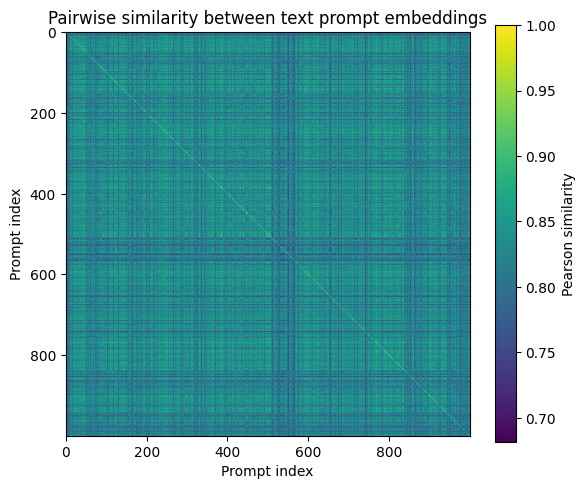

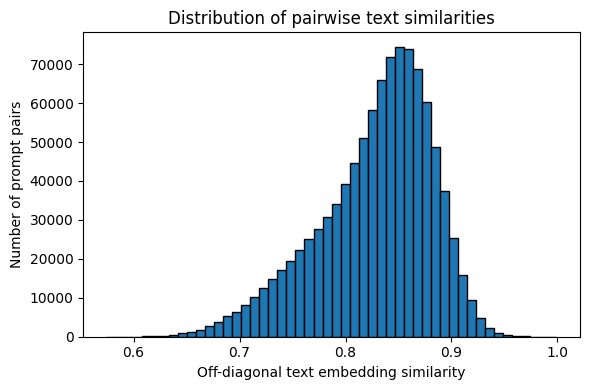

In [29]:
# Same similarity definition as in Task 2
text_similarities = np.corrcoef(text_embeddings)

mask = ~np.eye(text_similarities.shape[0], dtype=bool)
off_diag_text_sims = text_similarities[mask]

print("Text similarity matrix shape:", text_similarities.shape)
print("Off-diagonal min similarity:", float(off_diag_text_sims.min()))
print("Off-diagonal max similarity:", float(off_diag_text_sims.max()))
print("Off-diagonal mean similarity:", float(off_diag_text_sims.mean()))
print("Off-diagonal std similarity:", float(off_diag_text_sims.std()))

plt.figure(figsize=(6, 5))
plt.imshow(text_similarities, cmap="viridis", vmin=np.percentile(off_diag_text_sims, 1), vmax=1.0)
plt.colorbar(label="Pearson similarity")
plt.title("Pairwise similarity between text prompt embeddings")
plt.xlabel("Prompt index")
plt.ylabel("Prompt index")
plt.tight_layout()
plt.savefig(OUT_DIR / "task4_text_similarity_matrix.png", dpi=200)
plt.show()

plt.figure(figsize=(6, 4))
plt.hist(off_diag_text_sims, bins=50, edgecolor="black")
plt.xlabel("Off-diagonal text embedding similarity")
plt.ylabel("Number of prompt pairs")
plt.title("Distribution of pairwise text similarities")
plt.tight_layout()
plt.savefig(OUT_DIR / "task4_text_similarity_histogram.png", dpi=200)
plt.show()


### Task 4.d - Show five examples with closest and farthest textual neighbors

**Requirement:** show five text-prompt examples with their closest and farthest textual neighbors and comment on the results.


In [30]:
text_closest_indices, text_farthest_indices = find_closest_and_farthest(text_similarities)

text_neighbor_df = pd.DataFrame({
    "QueryIndex": np.arange(len(text_df)),
    "QueryFile": text_df["VideoFileName"].values,
    "QueryEF": text_df["EF"].astype(float).values,
    "QueryESV": text_df["ESV"].astype(float).values,
    "QueryEDV": text_df["EDV"].astype(float).values,
    "ClosestIndex": text_closest_indices,
    "FarthestIndex": text_farthest_indices,
})

text_neighbor_df["ClosestSimilarity"] = text_similarities[np.arange(len(text_df)), text_closest_indices]
text_neighbor_df["FarthestSimilarity"] = text_similarities[np.arange(len(text_df)), text_farthest_indices]
text_neighbor_df["ClosestEFdiff"] = np.abs(text_df["EF"].values - text_df.iloc[text_closest_indices]["EF"].values)
text_neighbor_df["FarthestEFdiff"] = np.abs(text_df["EF"].values - text_df.iloc[text_farthest_indices]["EF"].values)
text_neighbor_df["ClosestESVdiff"] = np.abs(text_df["ESV"].values - text_df.iloc[text_closest_indices]["ESV"].values)
text_neighbor_df["FarthestESVdiff"] = np.abs(text_df["ESV"].values - text_df.iloc[text_farthest_indices]["ESV"].values)
text_neighbor_df["ClosestEDVdiff"] = np.abs(text_df["EDV"].values - text_df.iloc[text_closest_indices]["EDV"].values)
text_neighbor_df["FarthestEDVdiff"] = np.abs(text_df["EDV"].values - text_df.iloc[text_farthest_indices]["EDV"].values)

display(text_neighbor_df.head())

# Summary for nearest and farthest text neighbors
summary_text_neighbors = pd.DataFrame({
    "NeighborType": ["Closest textual", "Farthest textual"],
    "MeanSimilarity": [text_neighbor_df["ClosestSimilarity"].mean(), text_neighbor_df["FarthestSimilarity"].mean()],
    "MedianSimilarity": [text_neighbor_df["ClosestSimilarity"].median(), text_neighbor_df["FarthestSimilarity"].median()],
    "MeanAbsEFDiff": [text_neighbor_df["ClosestEFdiff"].mean(), text_neighbor_df["FarthestEFdiff"].mean()],
    "MedianAbsEFDiff": [text_neighbor_df["ClosestEFdiff"].median(), text_neighbor_df["FarthestEFdiff"].median()],
    "MeanAbsESVDiff": [text_neighbor_df["ClosestESVdiff"].mean(), text_neighbor_df["FarthestESVdiff"].mean()],
    "MeanAbsEDVDiff": [text_neighbor_df["ClosestEDVdiff"].mean(), text_neighbor_df["FarthestEDVdiff"].mean()],
})

display(summary_text_neighbors)

# Inspect five examples
np.random.seed(24)
example_text_indices = np.random.choice(len(text_df), size=5, replace=False)

example_rows = []

for idx in example_text_indices:
    c_idx = int(text_closest_indices[idx])
    f_idx = int(text_farthest_indices[idx])

    print("=" * 100)
    print(f"QUERY index {idx} | similarity to closest={text_similarities[idx, c_idx]:.4f} | similarity to farthest={text_similarities[idx, f_idx]:.4f}")
    print("Query prompt:")
    print(prompts[idx])
    print("\nClosest textual neighbor:")
    print(prompts[c_idx])
    print("\nFarthest textual neighbor:")
    print(prompts[f_idx])

    example_rows.extend([
        {
            "Example": idx,
            "Type": "Query",
            "VideoFileName": text_df.iloc[idx]["VideoFileName"],
            "EF": text_df.iloc[idx]["EF"],
            "ESV": text_df.iloc[idx]["ESV"],
            "EDV": text_df.iloc[idx]["EDV"],
            "SimilarityToQuery": 1.0,
            "Prompt": prompts[idx],
        },
        {
            "Example": idx,
            "Type": "Closest",
            "VideoFileName": text_df.iloc[c_idx]["VideoFileName"],
            "EF": text_df.iloc[c_idx]["EF"],
            "ESV": text_df.iloc[c_idx]["ESV"],
            "EDV": text_df.iloc[c_idx]["EDV"],
            "SimilarityToQuery": text_similarities[idx, c_idx],
            "Prompt": prompts[c_idx],
        },
        {
            "Example": idx,
            "Type": "Farthest",
            "VideoFileName": text_df.iloc[f_idx]["VideoFileName"],
            "EF": text_df.iloc[f_idx]["EF"],
            "ESV": text_df.iloc[f_idx]["ESV"],
            "EDV": text_df.iloc[f_idx]["EDV"],
            "SimilarityToQuery": text_similarities[idx, f_idx],
            "Prompt": prompts[f_idx],
        },
    ])

examples_text_neighbors_df = pd.DataFrame(example_rows)
display(examples_text_neighbors_df)

examples_text_neighbors_df.to_csv(OUT_DIR / "task4_text_neighbor_examples.csv", index=False)
summary_text_neighbors.to_csv(OUT_DIR / "task4_text_neighbor_summary.csv", index=False)


,QueryIndex,QueryFile,QueryEF,QueryESV,QueryEDV,ClosestIndex,FarthestIndex,ClosestSimilarity,FarthestSimilarity,ClosestEFdiff,FarthestEFdiff,ClosestESVdiff,FarthestESVdiff,ClosestEDVdiff,FarthestEDVdiff
0,0,0X383838D5E679ACFE.avi,60.362023,41.323353,104.251921,826,199,0.954726,0.703538,0.048485,21.367747,7.963458,8.619890,20.242757,22.385436
1,1,0X7CE9AAE0242EF73D.avi,60.003217,59.433833,148.596534,334,627,0.941097,0.718947,0.026933,2.816928,7.167690,35.813606,17.832613,93.426761
2,2,0X705789F6BD6B3A46.avi,48.084950,13.636717,26.267367,917,574,0.940174,0.651942,0.042627,11.915220,69.961282,13.401831,134.893408,41.329288
3,3,0X7E37D63514270905.avi,46.733576,83.330765,156.441449,743,574,0.950642,0.687704,0.912149,13.266593,1.097338,56.292217,0.608435,88.844793
4,4,0X66C173C78E8F6EDF.avi,65.950831,31.211495,91.665951,674,77,0.944332,0.658369,0.057705,9.734577,13.825276,17.247310,40.517173,19.011661


,NeighborType,MeanSimilarity,MedianSimilarity,MeanAbsEFDiff,MedianAbsEFDiff,MeanAbsESVDiff,MeanAbsEDVDiff
0,Closest textual,0.945278,0.945644,1.989155,0.129386,9.322269,18.986582
1,Farthest textual,0.664333,0.665631,25.182712,23.571985,64.802747,69.489860


QUERY index 131 | similarity to closest=0.9517 | similarity to farthest=0.6669
Query prompt:
Left ventricle ejection fraction of 65.1% is observed with end systolic volume of 17.0 mL and end diastolic volume of 48.7 mL.

Closest textual neighbor:
Left ventricle ejection fraction of 65.1% is observed with end systolic volume of 15.0 mL and end diastolic volume of 42.9 mL.

Farthest textual neighbor:
Left ventricle ejection fraction of 53.0% is observed with end systolic volume of 71.1 mL and end diastolic volume of 151.1 mL.
QUERY index 354 | similarity to closest=0.9362 | similarity to farthest=0.6744
Query prompt:
Left ventricle ejection fraction of 61.5% is observed with end systolic volume of 49.7 mL and end diastolic volume of 129.2 mL.

Closest textual neighbor:
Left ventricle ejection fraction of 61.5% is observed with end systolic volume of 32.2 mL and end diastolic volume of 83.8 mL.

Farthest textual neighbor:
Left ventricle ejection fraction of 69.0% is observed with end syst

,Example,Type,VideoFileName,EF,ESV,EDV,SimilarityToQuery,Prompt
0,131,Query,0X14D6CCAC550E278B.avi,65.128713,16.969988,48.664646,1.000000,Left ventricle ejection fraction of 65.1% is o...
1,131,Closest,0X7302018616588BE1.avi,65.121954,14.964622,42.905564,0.951654,Left ventricle ejection fraction of 65.1% is o...
2,131,Farthest,0X6DE7AC1795267BA3.avi,52.971815,71.055156,151.090577,0.666887,Left ventricle ejection fraction of 53.0% is o...
3,354,Query,0X76F22089D5778788.avi,61.519584,49.730036,129.234663,1.000000,Left ventricle ejection fraction of 61.5% is o...
4,354,Closest,0X7093FB30EB363260.avi,61.541005,32.227679,83.797507,0.936151,Left ventricle ejection fraction of 61.5% is o...
5,354,Farthest,0X77F14DF18E757A6A.avi,69.034182,20.598234,66.519263,0.674391,Left ventricle ejection fraction of 69.0% is o...
6,982,Query,0X13E043A35E3EB490.avi,55.819376,41.465815,93.855203,1.000000,Left ventricle ejection fraction of 55.8% is o...
7,982,Closest,0X25651736878239CE.avi,58.754888,38.316669,92.899902,0.943464,Left ventricle ejection fraction of 58.8% is o...
8,982,Farthest,0X2CCCED512683D687.avi,60.000169,27.038548,67.596655,0.698304,Left ventricle ejection fraction of 60.0% is o...
9,476,Query,0X6DF0EE20A24FEF6A.avi,36.241194,34.619917,54.298251,1.000000,Left ventricle ejection fraction of 36.2% is o...


**Short interpretation for Task 4.d.** Text-text similarities are high, with an off-diagonal mean of approximately **0.828**, because the sentence template is nearly identical for all prompts. The closest textual neighbors have much smaller mean EF differences (**about 1.99 EF points**) than farthest textual neighbors (**about 25.18 EF points**). This indicates that the text embedding space captures measurement-related differences to some extent, but the high template similarity means that all prompts remain semantically close.


## Task 5 - Cross-Modal Similarity Evaluation

**Assignment scope:** calculate similarities between image embeddings and corresponding text-prompt embeddings across the selected 1000 samples, evaluate image-text alignment, show three example pairs and comment on whether the similarity values make sense.


  0%|          | 0/1000 [00:00<?, ?it/s]

Task 5: Cross-modal similarity results
N samples: 1000
Mean similarity:   0.2678
Median similarity: 0.2686
Std similarity:    0.0352
Min similarity:    0.1722
Max similarity:    0.3732


,VideoFileName,EF,ESV,EDV,Prompt,Similarity,FrameIndicesUsed
0,0X383838D5E679ACFE.avi,60.362023,41.323353,104.251921,Left ventricle ejection fraction of 60.4% is o...,0.268548,"[0, 85, 171]"
1,0X7CE9AAE0242EF73D.avi,60.003217,59.433833,148.596534,Left ventricle ejection fraction of 60.0% is o...,0.252924,"[0, 89, 179]"
2,0X705789F6BD6B3A46.avi,48.084950,13.636717,26.267367,Left ventricle ejection fraction of 48.1% is o...,0.263671,"[0, 44, 89]"
3,0X7E37D63514270905.avi,46.733576,83.330765,156.441449,Left ventricle ejection fraction of 46.7% is o...,0.232647,"[0, 67, 135]"
4,0X66C173C78E8F6EDF.avi,65.950831,31.211495,91.665951,Left ventricle ejection fraction of 66.0% is o...,0.248477,"[0, 94, 189]"


count    1000.000000
mean        0.267818
std         0.035164
min         0.172212
25%         0.243540
50%         0.268565
75%         0.292266
max         0.373243
Name: Similarity, dtype: float64

Saved Task 5 results to: outputs/task5_cross_modal_similarity_results.csv


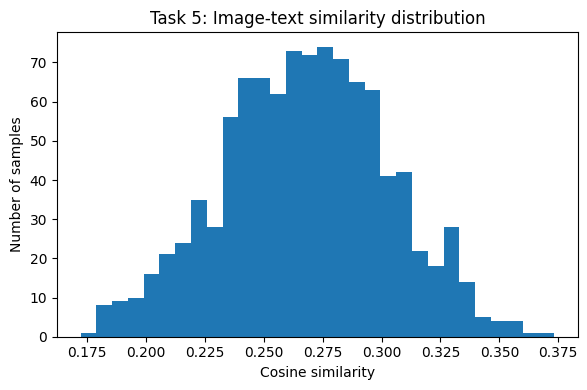

Saved similarity distribution figure to: outputs/task5_similarity_distribution.png


,ExampleType,VideoFileName,EF,ESV,EDV,Similarity,Prompt
501,Lowest similarity example,0X17AE431AF06F53AB.avi,55.670351,15.814105,35.673879,0.172212,Left ventricle ejection fraction of 55.7% is o...
0,Median similarity example,0X383838D5E679ACFE.avi,60.362023,41.323353,104.251921,0.268548,Left ventricle ejection fraction of 60.4% is o...
39,Highest similarity example,0X44A4EFFB743B7EBA.avi,62.765883,21.693352,58.262029,0.373243,Left ventricle ejection fraction of 62.8% is o...


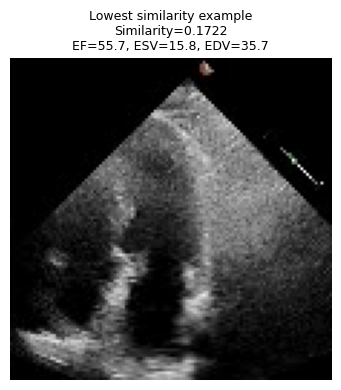

Lowest similarity example
Video: 0X17AE431AF06F53AB.avi
Similarity: 0.1722
Prompt:
Left ventricle ejection fraction of 55.7% is observed with end systolic volume of 15.8 mL and end diastolic volume of 35.7 mL.
Saved figure to: outputs/task5_lowest_similarity_example.png


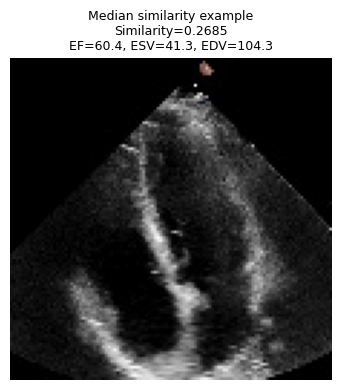

Median similarity example
Video: 0X383838D5E679ACFE.avi
Similarity: 0.2685
Prompt:
Left ventricle ejection fraction of 60.4% is observed with end systolic volume of 41.3 mL and end diastolic volume of 104.3 mL.
Saved figure to: outputs/task5_median_similarity_example.png


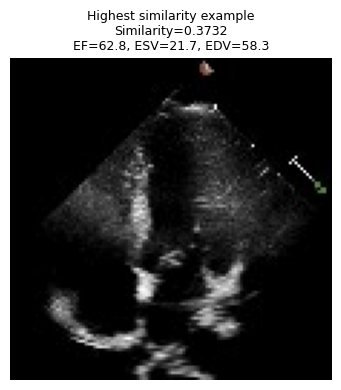

Highest similarity example
Video: 0X44A4EFFB743B7EBA.avi
Similarity: 0.3732
Prompt:
Left ventricle ejection fraction of 62.8% is observed with end systolic volume of 21.7 mL and end diastolic volume of 58.3 mL.
Saved figure to: outputs/task5_highest_similarity_example.png


In [32]:


import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm


model.eval()

tokenizer = open_clip.get_tokenizer("hf-hub:mkaichristensen/echo-clip")

def create_clinical_prompt(row):
    """
    Create corresponding text prompt for one video/sample.
    This prompt uses the ground-truth EF, ESV and EDV values.
    """
    return (
        f"Left ventricle ejection fraction of {float(row['EF']):.1f}% is observed "
        f"with end systolic volume of {float(row['ESV']):.1f} mL "
        f"and end diastolic volume of {float(row['EDV']):.1f} mL."
    )

def get_video_embedding(video_name, n_frames=3):
    """
    Obtain one video-level embedding by sampling frames,
    encoding them, and averaging normalized image embeddings.
    """
    frames, frame_indices = read_selected_frames(video_name, n_frames=n_frames)

    image_tensors = []
    for frame_rgb in frames:
        image_tensor = preprocess_val(Image.fromarray(frame_rgb))
        image_tensors.append(image_tensor)

    image_batch = torch.stack(image_tensors).to(DEVICE)

    with torch.no_grad():
        image_features = model.encode_image(image_batch)
        image_features = F.normalize(image_features, dim=-1)

        video_feature = image_features.mean(dim=0, keepdim=True)
        video_feature = F.normalize(video_feature, dim=-1)

    return video_feature, frame_indices

def get_text_embedding(prompt):
    """Encode and normalize one text prompt."""
    text_tokens = tokenizer([prompt]).to(DEVICE)

    with torch.no_grad():
        text_feature = model.encode_text(text_tokens)
        text_feature = F.normalize(text_feature, dim=-1)

    return text_feature

# 1. Calculate image-text similarities for all 1000 samples

task5_records = []

for idx, row in tqdm(sample_1000_valid.iterrows(), total=len(sample_1000_valid)):
    video_name = row["VideoFileName"]

    prompt = create_clinical_prompt(row)

    video_feature, frame_indices = get_video_embedding(video_name, n_frames=3)
    text_feature = get_text_embedding(prompt)

    # Cosine similarity because both embeddings are normalized
    similarity = float((video_feature * text_feature).sum().detach().cpu())

    task5_records.append({
        "VideoFileName": video_name,
        "EF": float(row["EF"]),
        "ESV": float(row["ESV"]),
        "EDV": float(row["EDV"]),
        "Prompt": prompt,
        "Similarity": similarity,
        "FrameIndicesUsed": str(frame_indices),
    })

task5_results = pd.DataFrame(task5_records)

# 2. Summary statistics

mean_similarity = task5_results["Similarity"].mean()
median_similarity = task5_results["Similarity"].median()
std_similarity = task5_results["Similarity"].std()
min_similarity = task5_results["Similarity"].min()
max_similarity = task5_results["Similarity"].max()

print("=" * 80)
print("Task 5: Cross-modal similarity results")
print(f"N samples: {len(task5_results)}")
print(f"Mean similarity:   {mean_similarity:.4f}")
print(f"Median similarity: {median_similarity:.4f}")
print(f"Std similarity:    {std_similarity:.4f}")
print(f"Min similarity:    {min_similarity:.4f}")
print(f"Max similarity:    {max_similarity:.4f}")
print("=" * 80)

display(task5_results.head())
display(task5_results["Similarity"].describe())

# 3. Save results

task5_results_path = OUT_DIR / "task5_cross_modal_similarity_results.csv"
task5_results.to_csv(task5_results_path, index=False)

print("Saved Task 5 results to:", task5_results_path)

# 4. Plot similarity distribution

plt.figure(figsize=(6, 4))
plt.hist(task5_results["Similarity"], bins=30)
plt.xlabel("Cosine similarity")
plt.ylabel("Number of samples")
plt.title("Task 5: Image-text similarity distribution")
plt.tight_layout()

similarity_plot_path = OUT_DIR / "task5_similarity_distribution.png"
plt.savefig(similarity_plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved similarity distribution figure to:", similarity_plot_path)

# 5. Show 3 example pairs:
#    lowest, median, highest similarity

lowest_idx = task5_results["Similarity"].idxmin()
median_idx = (task5_results["Similarity"] - task5_results["Similarity"].median()).abs().idxmin()
highest_idx = task5_results["Similarity"].idxmax()

example_indices = [lowest_idx, median_idx, highest_idx]
example_names = ["Lowest similarity example", "Median similarity example", "Highest similarity example"]

task5_examples = task5_results.loc[example_indices].copy()
task5_examples.insert(0, "ExampleType", example_names)

display(task5_examples[[
    "ExampleType",
    "VideoFileName",
    "EF",
    "ESV",
    "EDV",
    "Similarity",
    "Prompt"
]])

# 6. Visualize the 3 example image-text pairs

for _, ex in task5_examples.iterrows():
    frames, frame_indices = read_selected_frames(ex["VideoFileName"], n_frames=3)
    frame_rgb = frames[1]

    plt.figure(figsize=(4, 4))
    plt.imshow(frame_rgb)
    plt.axis("off")
    plt.title(
        f"{ex['ExampleType']}\n"
        f"Similarity={ex['Similarity']:.4f}\n"
        f"EF={ex['EF']:.1f}, ESV={ex['ESV']:.1f}, EDV={ex['EDV']:.1f}",
        fontsize=9
    )
    plt.tight_layout()

    safe_name = ex["ExampleType"].lower().replace(" ", "_")
    example_path = OUT_DIR / f"task5_{safe_name}.png"
    plt.savefig(example_path, dpi=200, bbox_inches="tight")
    plt.show()

    print("=" * 80)
    print(ex["ExampleType"])
    print("Video:", ex["VideoFileName"])
    print(f"Similarity: {ex['Similarity']:.4f}")
    print("Prompt:")
    print(ex["Prompt"])
    print("Saved figure to:", example_path)



## Task 6 - Zero-Shot Classification / EF Regression



Number of EF text prompts: 100
Text embedding shape: (100, 512)


  0%|          | 0/1000 [00:00<?, ?it/s]

Task 6 Zero-Shot EF Regression Results
N samples: 1000
MAE: 15.32 EF points
Median absolute error: 10.69 EF points
Standard deviation of absolute error: 14.10 EF points


,VideoFileName,TrueEF,PredictedEF,AbsoluteError,BestSimilarity,FrameIndicesUsed,MatchedPrompt
0,0X383838D5E679ACFE.avi,60.362023,65.0,4.637977,0.321844,"[0, 85, 171]",Left ventricle ejection fraction is 65%.
1,0X7CE9AAE0242EF73D.avi,60.003217,69.0,8.996783,0.293694,"[0, 89, 179]",Left ventricle ejection fraction is 69%.
2,0X705789F6BD6B3A46.avi,48.084950,100.0,51.915050,0.308157,"[0, 44, 89]",Left ventricle ejection fraction is 100%.
3,0X7E37D63514270905.avi,46.733576,55.0,8.266424,0.277639,"[0, 67, 135]",Left ventricle ejection fraction is 55%.
4,0X66C173C78E8F6EDF.avi,65.950831,61.0,4.950831,0.281287,"[0, 94, 189]",Left ventricle ejection fraction is 61%.


,TrueEF,PredictedEF,AbsoluteError,BestSimilarity
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,55.965718,69.459000,15.315200,0.298878
std,12.289293,16.782311,14.096244,0.018554
min,11.442630,2.000000,0.013501,0.229186
25%,52.162780,63.000000,5.241929,0.286482
50%,59.500043,70.000000,10.689751,0.300583
75%,64.084562,71.000000,21.892292,0.312364
max,84.452352,100.000000,83.982976,0.354048


Saved Task 6 results to: outputs/task6_zero_shot_ef_results.csv


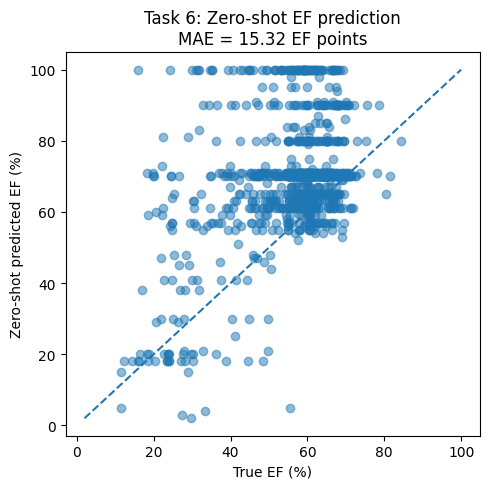

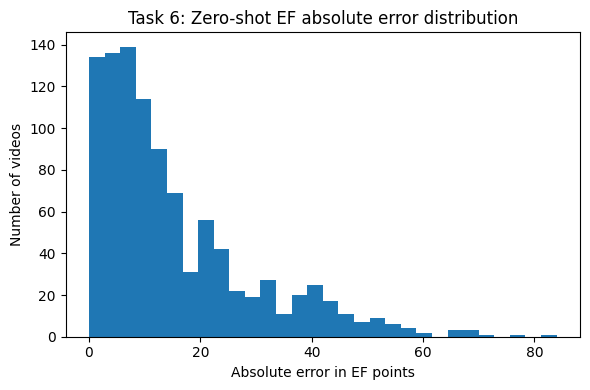

Saved figure to: outputs/task6_zero_shot_true_vs_predicted_ef.png
Saved figure to: outputs/task6_zero_shot_absolute_error_distribution.png


In [33]:


import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

model.eval()

tokenizer = open_clip.get_tokenizer("hf-hub:mkaichristensen/echo-clip")

# Use 100 EF classes/prompts from 1 to 100
ef_candidates = np.arange(1, 101)

def create_ef_prompt(ef_value):
    """
    Text prompt for one EF value.
    The assignment asks for 100 text embeddings with EF values from 1 to 100.
    """
    return f"Left ventricle ejection fraction is {ef_value}%."

ef_prompts = [create_ef_prompt(ef) for ef in ef_candidates]

# Encode all 100 EF text prompts

with torch.no_grad():
    text_tokens = tokenizer(ef_prompts).to(DEVICE)

    text_features = model.encode_text(text_tokens)
    text_features = F.normalize(text_features, dim=-1)

print("Number of EF text prompts:", len(ef_prompts))
print("Text embedding shape:", tuple(text_features.shape))

# Helper: get one video embedding

def get_video_embedding(video_name, n_frames=3):
    """
    Obtain one embedding for a video.

    The assignment says 'obtain embedding of a video'.
    Here, we sample multiple frames, encode each frame, normalize the frame embeddings,
    and average them to obtain one video-level embedding.
    """
    frames, frame_indices = read_selected_frames(video_name, n_frames=n_frames)

    image_tensors = []
    for frame_rgb in frames:
        image_tensor = preprocess_val(Image.fromarray(frame_rgb))
        image_tensors.append(image_tensor)

    image_batch = torch.stack(image_tensors).to(DEVICE)

    with torch.no_grad():
        image_features = model.encode_image(image_batch)
        image_features = F.normalize(image_features, dim=-1)

        video_feature = image_features.mean(dim=0, keepdim=True)
        video_feature = F.normalize(video_feature, dim=-1)

    return video_feature, frame_indices

# Zero-shot EF prediction for all 1000 samples

task6_records = []

for idx, row in tqdm(sample_1000_valid.iterrows(), total=len(sample_1000_valid)):
    video_name = row["VideoFileName"]
    true_ef = float(row["EF"])

    video_feature, frame_indices = get_video_embedding(video_name, n_frames=3)

    # Cosine similarity because both image/video and text embeddings are normalized
    similarities = video_feature @ text_features.T

    best_index = int(torch.argmax(similarities, dim=1).item())
    predicted_ef = float(ef_candidates[best_index])
    best_similarity = float(similarities[0, best_index].detach().cpu())

    abs_error = abs(predicted_ef - true_ef)

    task6_records.append({
        "VideoFileName": video_name,
        "TrueEF": true_ef,
        "PredictedEF": predicted_ef,
        "AbsoluteError": abs_error,
        "BestSimilarity": best_similarity,
        "FrameIndicesUsed": str(frame_indices),
        "MatchedPrompt": ef_prompts[best_index],
    })

task6_results = pd.DataFrame(task6_records)

# Calculate MAE

task6_mae = task6_results["AbsoluteError"].mean()
task6_median_ae = task6_results["AbsoluteError"].median()
task6_std_ae = task6_results["AbsoluteError"].std()

print("=" * 80)
print("Task 6 Zero-Shot EF Regression Results")
print(f"N samples: {len(task6_results)}")
print(f"MAE: {task6_mae:.2f} EF points")
print(f"Median absolute error: {task6_median_ae:.2f} EF points")
print(f"Standard deviation of absolute error: {task6_std_ae:.2f} EF points")
print("=" * 80)

display(task6_results.head())
display(task6_results.describe())

# Save results

task6_results_path = OUT_DIR / "task6_zero_shot_ef_results.csv"
task6_results.to_csv(task6_results_path, index=False)

print("Saved Task 6 results to:", task6_results_path)

# Plot predicted EF vs true EF

plt.figure(figsize=(5, 5))
plt.scatter(task6_results["TrueEF"], task6_results["PredictedEF"], alpha=0.5)

min_ef = min(task6_results["TrueEF"].min(), task6_results["PredictedEF"].min())
max_ef = max(task6_results["TrueEF"].max(), task6_results["PredictedEF"].max())

plt.plot([min_ef, max_ef], [min_ef, max_ef], linestyle="--")
plt.xlabel("True EF (%)")
plt.ylabel("Zero-shot predicted EF (%)")
plt.title(f"Task 6: Zero-shot EF prediction\nMAE = {task6_mae:.2f} EF points")
plt.tight_layout()

plot_path = OUT_DIR / "task6_zero_shot_true_vs_predicted_ef.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

# Plot absolute error distribution

plt.figure(figsize=(6, 4))
plt.hist(task6_results["AbsoluteError"], bins=30)
plt.xlabel("Absolute error in EF points")
plt.ylabel("Number of videos")
plt.title("Task 6: Zero-shot EF absolute error distribution")
plt.tight_layout()

error_plot_path = OUT_DIR / "task6_zero_shot_absolute_error_distribution.png"
plt.savefig(error_plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved figure to:", plot_path)
print("Saved figure to:", error_plot_path)



## Task 7 - Grad-CAM Visualization

**Assignment scope:** select five samples with the highest MAE and five samples with the lowest MAE from the zero-shot results, generate Grad-CAM visualizations for early, middle and final model layers, and compare correct versus incorrect prediction patterns.


,Group,VideoFileName,TrueEF,PredictedEF,AbsoluteError
0,Lowest MAE / most correct,0X5ECD55B830580E47.avi,71.013501,71.0,0.013501
1,Lowest MAE / most correct,0X4A35EEBF2751AE5C.avi,62.984242,63.0,0.015758
2,Lowest MAE / most correct,0X1EF97820A1259D69.avi,65.054459,65.0,0.054459
3,Lowest MAE / most correct,0X133F1774D5859CF4.avi,70.076753,70.0,0.076753
4,Lowest MAE / most correct,0X102F3D4CD5E10801.avi,46.915905,47.0,0.084095
5,Highest MAE / most incorrect,0XC8D1B3C80770006.avi,16.017024,100.0,83.982976
6,Highest MAE / most incorrect,0XB5CECBD29920B7B.avi,24.340894,100.0,75.659106
7,Highest MAE / most incorrect,0X243FDE8AE0A05B6F.avi,29.937452,100.0,70.062548
8,Highest MAE / most incorrect,0X541CBDC87C8A9938.avi,30.917441,100.0,69.082559
9,Highest MAE / most incorrect,0X4AE13510C2FEE40E.avi,31.645416,100.0,68.354584


Selected Grad-CAM layers:
Early layer: trunk.stem.0 | Conv2d
Middle layer: trunk.stages.2.blocks.11.conv_dw | Conv2d
Final layer: trunk.stages.3.blocks.2.conv_dw | Conv2d


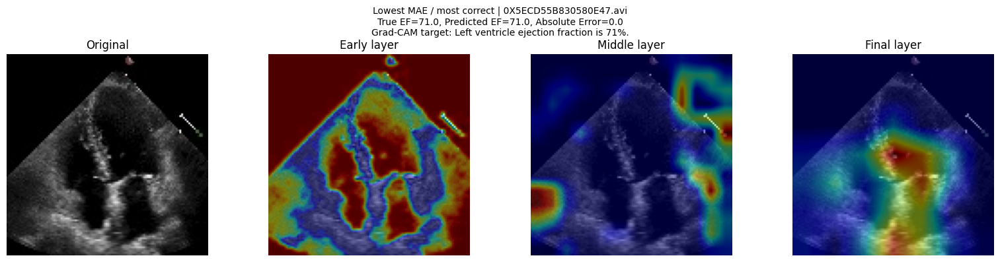

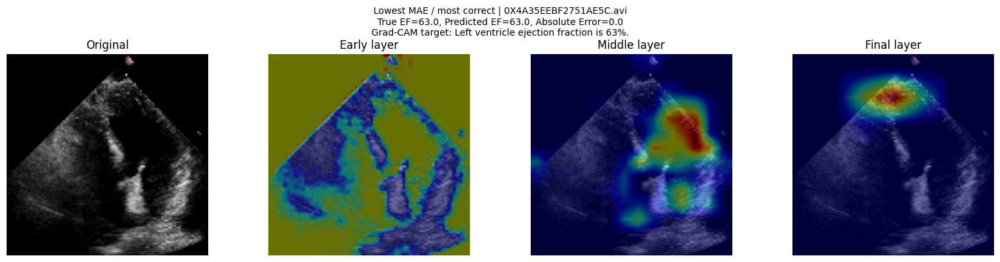

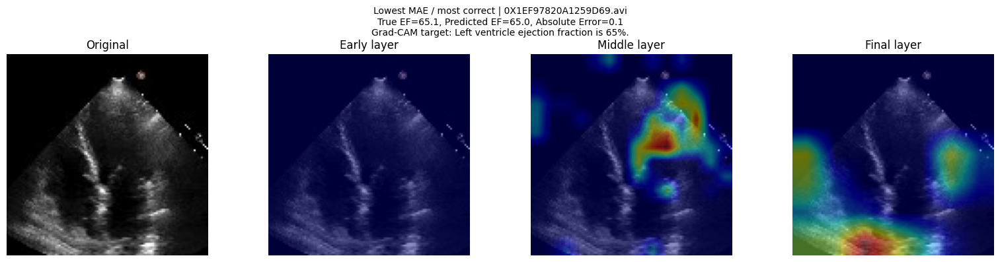

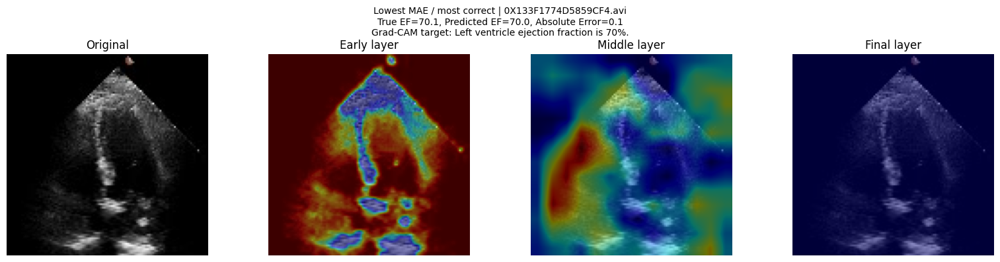

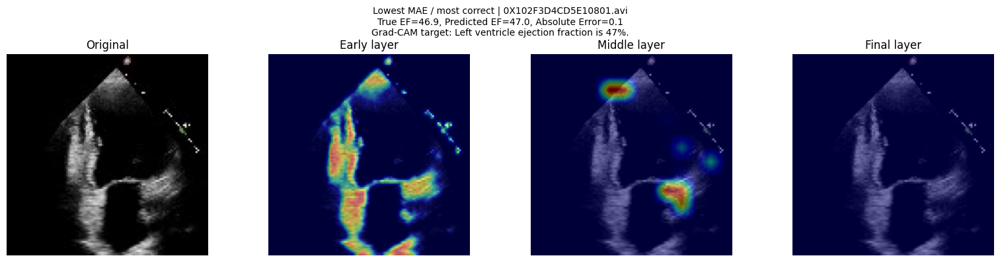

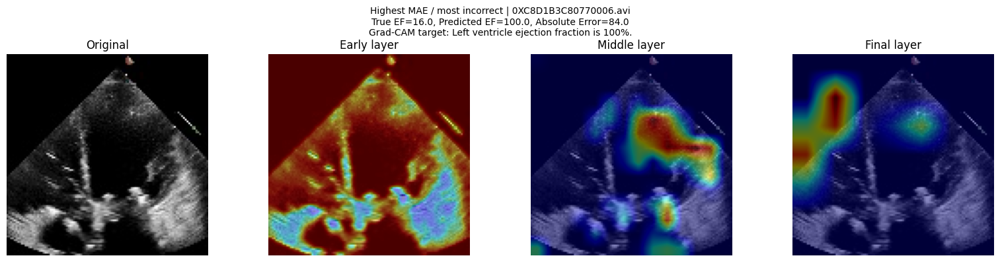

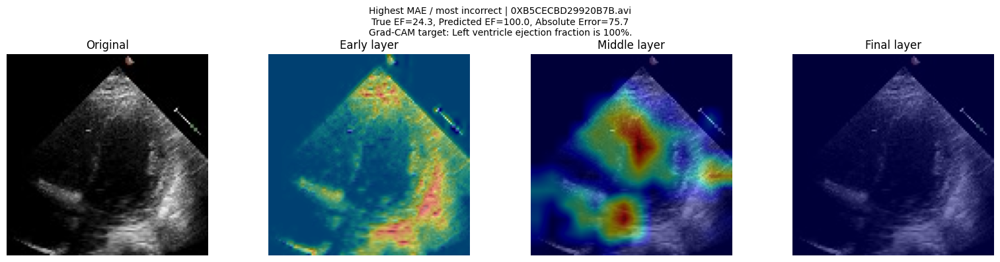

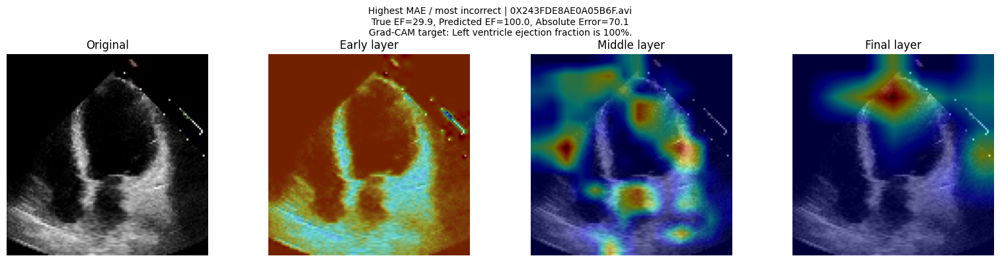

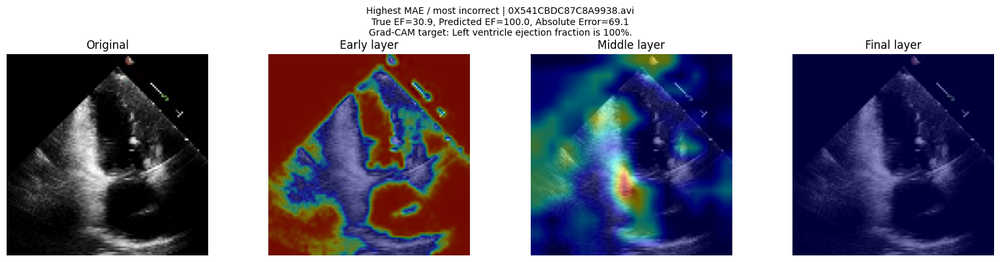

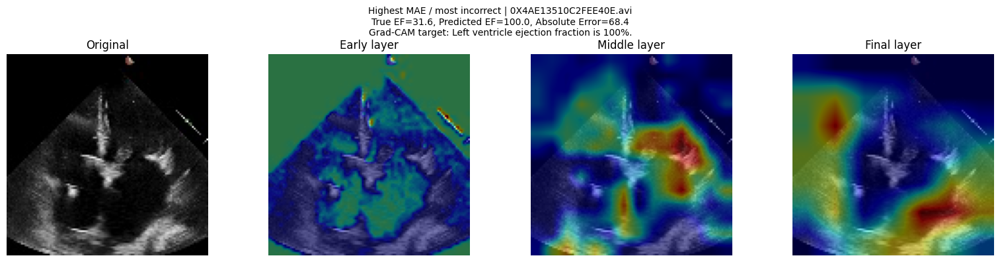

,Group,VideoFileName,FrameIndex,TrueEF,PredictedEF,AbsoluteError,GradCAMTargetPrompt,SimilarityScore,EarlyLayer,MiddleLayer,FinalLayer,SavedFigure
0,Lowest MAE / most correct,0X5ECD55B830580E47.avi,93,71.013501,71.0,0.013501,Left ventricle ejection fraction is 71%.,0.312542,trunk.stem.0,trunk.stages.2.blocks.11.conv_dw,trunk.stages.3.blocks.2.conv_dw,outputs/task7_gradcam_low_mae_1.png
1,Lowest MAE / most correct,0X4A35EEBF2751AE5C.avi,85,62.984242,63.0,0.015758,Left ventricle ejection fraction is 63%.,0.308543,trunk.stem.0,trunk.stages.2.blocks.11.conv_dw,trunk.stages.3.blocks.2.conv_dw,outputs/task7_gradcam_low_mae_2.png
2,Lowest MAE / most correct,0X1EF97820A1259D69.avi,109,65.054459,65.0,0.054459,Left ventricle ejection fraction is 65%.,0.288208,trunk.stem.0,trunk.stages.2.blocks.11.conv_dw,trunk.stages.3.blocks.2.conv_dw,outputs/task7_gradcam_low_mae_3.png
3,Lowest MAE / most correct,0X133F1774D5859CF4.avi,90,70.076753,70.0,0.076753,Left ventricle ejection fraction is 70%.,0.322709,trunk.stem.0,trunk.stages.2.blocks.11.conv_dw,trunk.stages.3.blocks.2.conv_dw,outputs/task7_gradcam_low_mae_4.png
4,Lowest MAE / most correct,0X102F3D4CD5E10801.avi,99,46.915905,47.0,0.084095,Left ventricle ejection fraction is 47%.,0.293863,trunk.stem.0,trunk.stages.2.blocks.11.conv_dw,trunk.stages.3.blocks.2.conv_dw,outputs/task7_gradcam_low_mae_5.png
5,Highest MAE / most incorrect,0XC8D1B3C80770006.avi,65,16.017024,100.0,83.982976,Left ventricle ejection fraction is 100%.,0.292137,trunk.stem.0,trunk.stages.2.blocks.11.conv_dw,trunk.stages.3.blocks.2.conv_dw,outputs/task7_gradcam_high_mae_6.png
6,Highest MAE / most incorrect,0XB5CECBD29920B7B.avi,104,24.340894,100.0,75.659106,Left ventricle ejection fraction is 100%.,0.278554,trunk.stem.0,trunk.stages.2.blocks.11.conv_dw,trunk.stages.3.blocks.2.conv_dw,outputs/task7_gradcam_high_mae_7.png
7,Highest MAE / most incorrect,0X243FDE8AE0A05B6F.avi,68,29.937452,100.0,70.062548,Left ventricle ejection fraction is 100%.,0.265827,trunk.stem.0,trunk.stages.2.blocks.11.conv_dw,trunk.stages.3.blocks.2.conv_dw,outputs/task7_gradcam_high_mae_8.png
8,Highest MAE / most incorrect,0X541CBDC87C8A9938.avi,82,30.917441,100.0,69.082559,Left ventricle ejection fraction is 100%.,0.280867,trunk.stem.0,trunk.stages.2.blocks.11.conv_dw,trunk.stages.3.blocks.2.conv_dw,outputs/task7_gradcam_high_mae_9.png
9,Highest MAE / most incorrect,0X4AE13510C2FEE40E.avi,62,31.645416,100.0,68.354584,Left ventricle ejection fraction is 100%.,0.312056,trunk.stem.0,trunk.stages.2.blocks.11.conv_dw,trunk.stages.3.blocks.2.conv_dw,outputs/task7_gradcam_high_mae_10.png


Saved Task 7 summary to: outputs/task7_gradcam_summary.csv


In [34]:


import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image

# Load Task 6 results if needed

try:
    task6_results
except NameError:
    task6_results = pd.read_csv(OUT_DIR / "task6_zero_shot_ef_results.csv")

model.eval()

# 1. Helper functions

def normalize_map(x):
    x = np.asarray(x, dtype=np.float32)
    x = x - np.nanmin(x)
    return x / (np.nanmax(x) + 1e-8)

def read_single_video_frame(video_name):
    """Use the middle of three sampled frames."""
    frames, frame_indices = read_selected_frames(video_name, n_frames=3)
    return frames[1], frame_indices[1]

def create_ef_prompt(ef_value):
    """Same style as Task 6 zero-shot EF prompts."""
    return f"Left ventricle ejection fraction is {int(round(float(ef_value)))}%."

def tensor_to_nchw(x):
    """
    Convert activation/gradient tensor to NCHW if necessary.
    Conv layers usually return NCHW, but this keeps the code safer.
    """
    if x.ndim != 4:
        raise RuntimeError(f"Expected 4D tensor, got shape {tuple(x.shape)}")

    # If second dimension is likely channels, keep NCHW.
    if x.shape[1] <= x.shape[-1] or x.shape[1] > 8:
        return x

    # Otherwise assume NHWC and convert to NCHW.
    return x.permute(0, 3, 1, 2)

def find_conv_layers_for_gradcam(visual_encoder):
    """
    Select early, middle and final Conv2d layers from the visual encoder.
    This is suitable for EchoCLIP's ConvNeXt visual encoder.
    """
    conv_layers = []
    for name, layer in visual_encoder.named_modules():
        if isinstance(layer, torch.nn.Conv2d):
            conv_layers.append((name, layer))

    if len(conv_layers) < 3:
        raise RuntimeError(f"Need at least 3 Conv2d layers, found {len(conv_layers)}.")

    early = conv_layers[0]
    middle = conv_layers[len(conv_layers) // 2]
    final = conv_layers[-1]

    return {
        "Early layer": early,
        "Middle layer": middle,
        "Final layer": final,
    }

def compute_gradcam_for_layers(frame_rgb, predicted_ef, selected_layers):
    """
    Compute Grad-CAM maps for early, middle and final selected layers.
    The score is the cosine similarity between the image embedding and
    the text embedding of the predicted EF prompt.
    """
    activations = {}
    gradients = {}
    handles = []

    def make_forward_hook(layer_label):
        def forward_hook(module, input, output):
            activations[layer_label] = output
        return forward_hook

    def make_backward_hook(layer_label):
        def backward_hook(module, grad_input, grad_output):
            gradients[layer_label] = grad_output[0]
        return backward_hook

    for layer_label, (layer_name, layer_module) in selected_layers.items():
        handles.append(layer_module.register_forward_hook(make_forward_hook(layer_label)))
        handles.append(layer_module.register_full_backward_hook(make_backward_hook(layer_label)))

    try:
        image_tensor = preprocess_val(Image.fromarray(frame_rgb)).unsqueeze(0).to(DEVICE)

        prompt = create_ef_prompt(predicted_ef)
        text_tokens = tokenizer([prompt]).to(DEVICE)

        model.zero_grad(set_to_none=True)

        image_features = model.encode_image(image_tensor)
        text_features = model.encode_text(text_tokens)

        image_features = F.normalize(image_features, dim=-1)
        text_features = F.normalize(text_features, dim=-1)

        score = (image_features * text_features).sum()
        score.backward()

        gradcam_maps = {}

        for layer_label in selected_layers.keys():
            act = activations[layer_label]
            grad = gradients[layer_label]

            act = tensor_to_nchw(act)
            grad = tensor_to_nchw(grad)

            # Grad-CAM weighting
            weights = grad.mean(dim=(2, 3), keepdim=True)
            cam = (weights * act).sum(dim=1, keepdim=True)
            cam = F.relu(cam)

            cam = F.interpolate(
                cam,
                size=frame_rgb.shape[:2],
                mode="bilinear",
                align_corners=False
            )

            heatmap = cam.squeeze().detach().cpu().numpy()
            heatmap = normalize_map(heatmap)

            gradcam_maps[layer_label] = heatmap

        return gradcam_maps, float(score.detach().cpu()), prompt

    finally:
        for h in handles:
            h.remove()

def show_gradcam_row(frame_rgb, gradcam_maps, title, save_path=None):
    """Show original frame plus early/middle/final Grad-CAM overlays."""
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    axes[0].imshow(frame_rgb)
    axes[0].set_title("Original")
    axes[0].axis("off")

    for ax, layer_label in zip(axes[1:], ["Early layer", "Middle layer", "Final layer"]):
        ax.imshow(frame_rgb)
        ax.imshow(gradcam_maps[layer_label], cmap="jet", alpha=0.45)
        ax.set_title(layer_label)
        ax.axis("off")

    fig.suptitle(title, fontsize=10)
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")

    plt.show()

# 2. Select 5 lowest-MAE and 5 highest-MAE samples

task6_sorted_low = task6_results.sort_values("AbsoluteError", ascending=True).head(5).copy()
task6_sorted_high = task6_results.sort_values("AbsoluteError", ascending=False).head(5).copy()

task6_sorted_low["Group"] = "Lowest MAE / most correct"
task6_sorted_high["Group"] = "Highest MAE / most incorrect"

task7_samples = pd.concat([task6_sorted_low, task6_sorted_high], axis=0).reset_index(drop=True)

display(task7_samples[[
    "Group",
    "VideoFileName",
    "TrueEF",
    "PredictedEF",
    "AbsoluteError"
]])

# 3. Select early, middle and final visual layers

selected_layers = find_conv_layers_for_gradcam(model.visual)

print("Selected Grad-CAM layers:")
for label, (name, layer) in selected_layers.items():
    print(f"{label}: {name} | {layer.__class__.__name__}")

# 4. Generate Grad-CAM visualizations

task7_records = []

for i, row in task7_samples.iterrows():
    video_name = row["VideoFileName"]
    true_ef = float(row["TrueEF"])
    predicted_ef = float(row["PredictedEF"])
    abs_error = float(row["AbsoluteError"])
    group = row["Group"]

    frame_rgb, frame_index = read_single_video_frame(video_name)

    gradcam_maps, score, prompt = compute_gradcam_for_layers(
        frame_rgb=frame_rgb,
        predicted_ef=predicted_ef,
        selected_layers=selected_layers
    )

    safe_group = "low_mae" if "Lowest" in group else "high_mae"
    save_path = OUT_DIR / f"task7_gradcam_{safe_group}_{i+1}.png"

    title = (
        f"{group} | {video_name}\n"
        f"True EF={true_ef:.1f}, Predicted EF={predicted_ef:.1f}, "
        f"Absolute Error={abs_error:.1f}\n"
        f"Grad-CAM target: {prompt}"
    )

    show_gradcam_row(
        frame_rgb=frame_rgb,
        gradcam_maps=gradcam_maps,
        title=title,
        save_path=save_path
    )

    task7_records.append({
        "Group": group,
        "VideoFileName": video_name,
        "FrameIndex": frame_index,
        "TrueEF": true_ef,
        "PredictedEF": predicted_ef,
        "AbsoluteError": abs_error,
        "GradCAMTargetPrompt": prompt,
        "SimilarityScore": score,
        "EarlyLayer": selected_layers["Early layer"][0],
        "MiddleLayer": selected_layers["Middle layer"][0],
        "FinalLayer": selected_layers["Final layer"][0],
        "SavedFigure": str(save_path)
    })


task7_results = pd.DataFrame(task7_records)
display(task7_results)

task7_results_path = OUT_DIR / "task7_gradcam_summary.csv"
task7_results.to_csv(task7_results_path, index=False)

print("Saved Task 7 summary to:", task7_results_path)

